# 1. Import Libraries

In [26]:
from pathlib import Path
import hashlib # Detect duplicates
from google.colab import drive
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image # open images and process them
from sklearn.model_selection import train_test_split

print('Libraries loaded.')

Libraries loaded.


# 2. Data Collection

### Connect Google Drive

In [27]:

# Mount Google Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Extract Dataset from Google Drive

In [28]:

# Dataset ZIP location in Google Drive
ZIP_PATH = Path('/content/drive/MyDrive/Fruits_Vegetables_Dataset(12000).zip')

# Local extraction directory
EXTRACT_DIR = Path('/content/Dataset')

# Check ZIP exists
if not ZIP_PATH.is_file():
    raise FileNotFoundError(f'Dataset ZIP not found: {ZIP_PATH}')

# Extract dataset only if needed
DATASET_PATH = EXTRACT_DIR / 'Fruits_Vegetables_Dataset(12000)'

if not DATASET_PATH.is_dir():
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)

    print('Dataset extracted successfully!')

print('Extraction directory:', EXTRACT_DIR)

Extraction directory: /content/Dataset


## Dataset Path

In [29]:

# Validate extracted dataset folder
if not DATASET_PATH.is_dir():
    raise FileNotFoundError(
        f'Dataset folder not found: {DATASET_PATH}'
    )

print('Dataset path:', DATASET_PATH)


Dataset path: /content/Dataset/Fruits_Vegetables_Dataset(12000)


## Inspect Folders

In [30]:
for group in sorted(DATASET_PATH.iterdir()):
    if group.is_dir():
        print(f'{group.name}/')

        for folder in sorted(group.iterdir()):
            if folder.is_dir():
                count = sum(1 for item in folder.iterdir() if item.is_file())
                print(f'  {folder.name}/ ({count} files)')

Fruits/
  FreshApple/ (612 files)
  FreshBanana/ (624 files)
  FreshMango/ (605 files)
  FreshOrange/ (609 files)
  FreshStrawberry/ (603 files)
  RottenApple/ (588 files)
  RottenBanana/ (576 files)
  RottenMango/ (593 files)
  RottenOrange/ (591 files)
  RottenStrawberry/ (596 files)
Vegetables/
  FreshBellpepper/ (611 files)
  FreshCarrot/ (620 files)
  FreshCucumber/ (608 files)
  FreshPotato/ (615 files)
  FreshTomato/ (604 files)
  RottenBellpepper/ (591 files)
  RottenCarrot/ (580 files)
  RottenCucumber/ (593 files)
  RottenPotato/ (585 files)
  RottenTomato/ (596 files)


## Build Image Inventory

In [31]:
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.webp', '.bmp', '.tif', '.tiff'} # SET OF IMAGE EXTENSIONS (UNIQUE)

records = []
for path in sorted(DATASET_PATH.rglob('*')): # Search recursively for all files and folders in the dataset path
    if not path.is_file():
        continue
    original_class = path.parent.name
    condition = next((name for name in ('Fresh', 'Rotten')
                      if original_class.startswith(name)), None)
    food_type = original_class[len(condition):].strip() if condition else '' # Strip removes whitespace from the string and return the name if food
    records.append({
        'path':           str(path),
        'folder':         str(path.parent.relative_to(DATASET_PATH)),
        'original_class': original_class,
        'condition':      condition,
        'food_type':      food_type,
        'extension':      path.suffix.lower(), # extension of the file in lowercase
    })

In [32]:
all_files  = pd.DataFrame(records)
image_data = all_files[all_files['extension'].isin(IMAGE_EXTENSIONS)].copy()

print(f'Total files found:               {len(all_files):,}')
print(f'Images with supported extension: {len(image_data):,}')
print(f'Unique class folders:            {image_data["folder"].nunique()}')
print('Food types:', ', '.join(sorted(image_data.loc[image_data['food_type'].ne(''), 'food_type'].unique())))

condition_counts = image_data['condition'].value_counts().reindex(['Fresh', 'Rotten'], fill_value=0)
display(condition_counts.rename('images').to_frame())

Total files found:               12,000
Images with supported extension: 12,000
Unique class folders:            20
Food types: Apple, Banana, Bellpepper, Carrot, Cucumber, Mango, Orange, Potato, Strawberry, Tomato


,images
condition,
Fresh,6111
Rotten,5889


# 3. Data Visualization (Before Cleaning)

## Fresh vs. Rotten Count

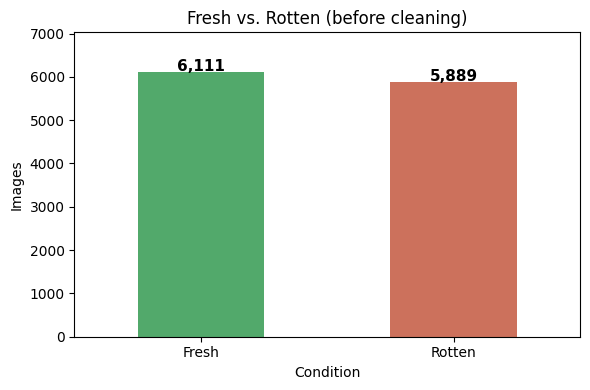

In [33]:
# Figure is the canvas, Subplot is a plot inside it, and Axes is where data is drawn.
fig, ax = plt.subplots(figsize=(6, 4))
condition_counts.plot.bar(ax=ax, color=['#52a96b', '#cc715c'], rot=0)
ax.set(title='Fresh vs. Rotten (before cleaning)', xlabel='Condition', ylabel='Images')
for i, v in enumerate(condition_counts):
    ax.text(i, v + 20, f'{v:,}', ha='center', fontsize=11, fontweight='bold')
ax.set_ylim(0, condition_counts.max() * 1.15)
plt.tight_layout() # For better spacing of the plot elements
plt.show()

## Images by Food Type

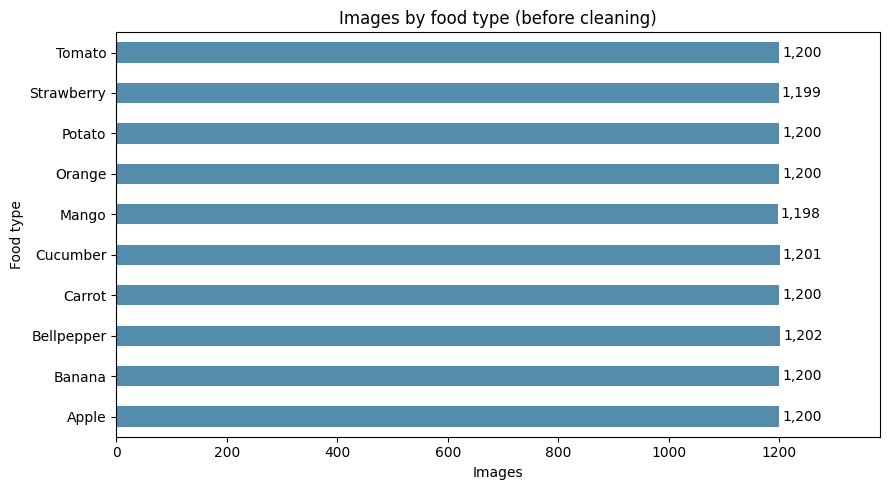

In [34]:
food_counts = image_data.loc[image_data['food_type'].ne(''), 'food_type'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 5))
food_counts.plot.barh(ax=ax, color='#568cab')
ax.set(title='Images by food type (before cleaning)', xlabel='Images', ylabel='Food type')
for i, v in enumerate(food_counts):
    ax.text(v + 5, i, f'{v:,}', va='center')
ax.set_xlim(0, food_counts.max() * 1.15) #  Set x-axis limit to 15% more than the maximum value for better visibility of text labels
plt.tight_layout() # for better spacing of the plot elements
plt.show()

## Sample Images

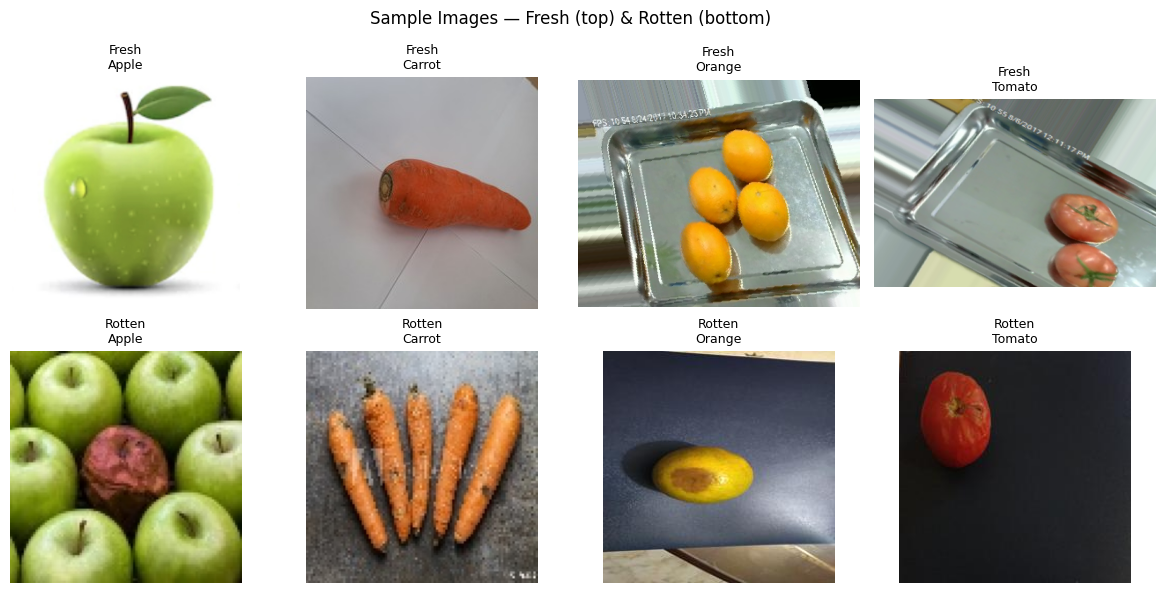

In [35]:
sample_foods = sorted(food_counts.index)[::3]
fig, axes = plt.subplots(2, len(sample_foods), figsize=(12, 6), squeeze=False)

for row, condition in enumerate(['Fresh', 'Rotten']):
    for col, food in enumerate(sample_foods):
        ax = axes[row, col]
        candidates = image_data[(image_data['condition'] == condition) &
                                (image_data['food_type'] == food)]
        shown = False
        for path in candidates.sample(frac=1, random_state=42)['path']: # Select a random of images
            try:
                with Image.open(path) as img:
                    img = img.convert('RGB')
                    img.thumbnail((400, 400))
                    ax.imshow(img)
                shown = True
                break
            except Exception:
                continue
        label = f'{condition}\n{food}' if shown else f'No {condition}\n{food}'
        ax.set_title(label, fontsize=9)
        ax.axis('off') # Hide the axes for a cleaner look

plt.suptitle('Sample Images — Fresh (top) & Rotten (bottom)', fontsize=12)
plt.tight_layout()
plt.show()

# 4. Data Preprocessing

## Image Validation & Quality Checks

In [36]:
SUPPORTED_FORMATS = {'JPEG', 'PNG', 'WEBP', 'BMP', 'TIFF'}

valid_records, issues = [], []

for record in all_files.to_dict('records'):
    path   = Path(record['path'])
    reason = None

    if path.stat().st_size == 0:
        reason = 'Empty file'
    elif record['extension'] not in IMAGE_EXTENSIONS:
        reason = 'Unsupported extension'
    elif record['condition'] is None or not record['food_type']:
        reason = 'Invalid folder name'
    else:
        # open the image to check if it is readable and in a supported format
        try:
            with Image.open(path) as img:
                if img.format not in SUPPORTED_FORMATS:
                    reason = f'Unsupported format: {img.format}'
                else:
                    img.load()
            if reason is None:
                record['sha256'] = hashlib.sha256(path.read_bytes()).hexdigest() #  Detect duplicates
                valid_records.append(record)
        except Exception as e:
            reason = f'Unreadable: {e}'

    if reason:
        issues.append({'path': str(path.relative_to(DATASET_PATH)), 'reason': reason})

In [37]:
cleaning_issues = pd.DataFrame(issues, columns=['path', 'reason'])
valid_data      = pd.DataFrame(valid_records)

print(f'Files excluded by basic checks:  {len(cleaning_issues):,}')
print(f'Readable images before dedup:    {len(valid_data):,}')
if not cleaning_issues.empty:
    display(cleaning_issues)

Files excluded by basic checks:  1
Readable images before dedup:    11,999


,path,reason
0,Vegetables/FreshPotato/freshPotato (597).jpg,Unsupported format: MPO


## Remove Exact Duplicates & Conflicting Labels

In [38]:
exact_dup_copies = int(valid_data.duplicated('sha256').sum())  # Count duplicate copies

cond_per_hash = valid_data.groupby('sha256')['condition'].nunique()  # Count unique labels per hash

conflicting_hashes = cond_per_hash[cond_per_hash > 1].index  # Find conflicting labels

conflicting_data = valid_data[valid_data['sha256'].isin(conflicting_hashes)].copy()  # Select conflicting images

consistent_data = valid_data[~valid_data['sha256'].isin(conflicting_hashes)].copy()  # Keep consistent images

dup_copies_removed = int(consistent_data.duplicated('sha256').sum())  # Count remaining duplicates

usable_data = consistent_data.drop_duplicates('sha256').reset_index(drop=True)  # Remove duplicates and reset index

if usable_data.empty:  # Check empty dataset
    raise ValueError('No usable images after deduplication.')  # Stop if no images

print(f'Exact duplicate copies found:          {exact_dup_copies:,}')
print(f'Conflicting-label groups excluded:     {len(conflicting_hashes):,}')
print(f'Images excluded (conflicting labels):  {len(conflicting_data):,}')
print(f'Remaining duplicate copies excluded:   {dup_copies_removed:,}')
print(f'Total usable images:                   {len(usable_data):,}')

# Sanity checks
assert len(all_files) == len(cleaning_issues) + len(conflicting_data) + dup_copies_removed + len(usable_data)  # Verify file counts

assert usable_data['sha256'].is_unique  # Ensure unique hashes

Exact duplicate copies found:          232
Conflicting-label groups excluded:     2
Images excluded (conflicting labels):  5
Remaining duplicate copies excluded:   229
Total usable images:                   11,765


## Visualization After Cleaning

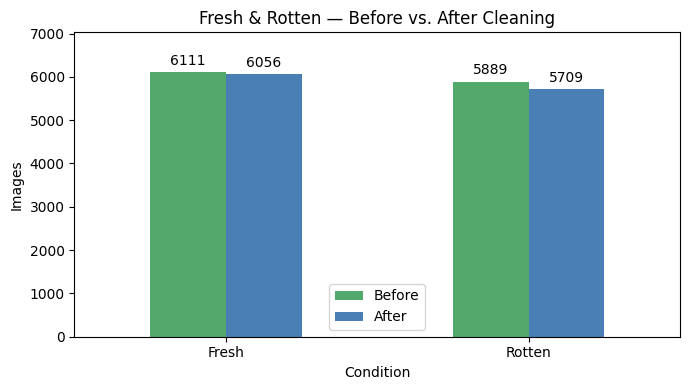

In [39]:
# Count images after cleaning
clean_condition_counts = usable_data['condition'].value_counts().reindex(['Fresh', 'Rotten'], fill_value=0)

# Create bar chart
fig, ax = plt.subplots(figsize=(7, 4))

before_after = pd.DataFrame({
    'Before': condition_counts,
    'After': clean_condition_counts,
})

before_after.plot.bar(ax=ax, color=['#52a96b', '#4a7fb5'], rot=0)

ax.set_title('Fresh & Rotten — Before vs. After Cleaning')
ax.set_xlabel('Condition')
ax.set_ylabel('Images')
ax.set_ylim(0, before_after.max().max() * 1.15)

# Show values above bars
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.tight_layout()
plt.show()

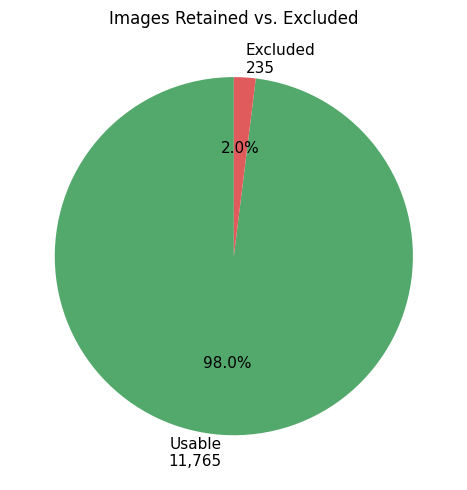

In [40]:
# Calculate retained and excluded images
total = len(all_files)
usable_count = len(usable_data)
excluded = total - usable_count

# Create pie chart
fig, ax = plt.subplots(figsize=(6, 5))

ax.pie(
    [usable_count, excluded],
    labels=[f'Usable\n{usable_count:,}', f'Excluded\n{excluded:,}'],
    colors=['#52a96b', '#e05c5c'],
    autopct='%1.1f%%', # Display percentage with one decimal place autotmatically
    startangle=90,
    textprops={'fontsize': 11},
)

ax.set_title('Images Retained vs. Excluded')

plt.tight_layout()
plt.show()

## Binary Target Mapping

In [41]:
LABEL_MAP  = {'Fresh': 0, 'Rotten': 1}
IMAGE_SIZE = (224, 224)

usable_data['target'] = usable_data['condition'].map(LABEL_MAP).astype('int64')
assert set(usable_data['target'].unique()) == {0, 1}

display(usable_data.groupby(['condition', 'target']).size().rename('images').to_frame())

,,images
condition,target,
Fresh,0,6056
Rotten,1,5709


## Preprocessing Function

In [42]:
def preprocess_image(path):
    """RGB → resize 224×224 → float32 in [0, 1]."""
    with Image.open(path) as img:
        img = img.convert('RGB').resize(IMAGE_SIZE, Image.Resampling.BILINEAR) # BILINEAR sampling for better quality when resizing
        return np.asarray(img, dtype=np.float32) / 255.0 # Normalize pixel values to [0, 1]

# Preview on 4 images (2 Fresh + 2 Rotten)
preview_data   = usable_data.groupby('condition', group_keys=False).sample(n=2, random_state=42)
preview_images = np.stack([preprocess_image(p) for p in preview_data['path']])
preview_labels = preview_data['target'].to_numpy(dtype=np.int64)

print('Preview shape:', preview_images.shape)      # (4, 224, 224, 3)
print('Dtype:        ', preview_images.dtype)      # float32
print(f'Pixel range:   [{preview_images.min():.3f}, {preview_images.max():.3f}]')
print('Targets:      ', preview_labels)

assert preview_images.shape == (4, 224, 224, 3)
assert preview_images.dtype == np.float32
assert 0 <= preview_images.min() <= preview_images.max() <= 1

Preview shape: (4, 224, 224, 3)
Dtype:         float32
Pixel range:   [0.000, 1.000]
Targets:       [0 0 1 1]


# 5. Data Splitting

## Train / Validation / Test Split

In [43]:
RANDOM_STATE = 42

combined_labels  = usable_data['condition'] + '|' + usable_data['food_type']
combined_counts  = combined_labels.value_counts()
use_food_strat   = (combined_counts.min() >= 10 and
                    len(usable_data) * 0.10 >= len(combined_counts))
stratify_labels  = combined_labels if use_food_strat else usable_data['condition']

train_data, held_out = train_test_split(
    usable_data, test_size=0.20, random_state=RANDOM_STATE, stratify=stratify_labels)

held_strat = (held_out['condition'] + '|' + held_out['food_type']
              if use_food_strat else held_out['condition'])
val_data, test_data  = train_test_split(
    held_out, test_size=0.50, random_state=RANDOM_STATE, stratify=held_strat)

train_data = train_data.reset_index(drop=True)
val_data   = val_data.reset_index(drop=True)
test_data  = test_data.reset_index(drop=True)

splits = {'Training': train_data, 'Validation': val_data, 'Testing': test_data}
print('Stratification:', 'condition + food_type' if use_food_strat else 'condition only')

Stratification: condition + food_type


## Split Summary & Visualization

In [44]:
# -- Summary table --
rows = []
for name, frame in splits.items():
    rows.append({
        'Split':      name,
        'Samples':    len(frame),
        'Percentage': f"{100 * len(frame) / len(usable_data):.1f}%",
        'Fresh (0)':  int((frame['target'] == 0).sum()),
        'Rotten (1)': int((frame['target'] == 1).sum()),
    })
display(pd.DataFrame(rows).set_index('Split'))

# -- Food-type distribution across splits --
food_split = pd.DataFrame({
    name: frame['food_type'].value_counts() for name, frame in splits.items()
}).fillna(0).astype(int).sort_index()
display(food_split)



,Samples,Percentage,Fresh (0),Rotten (1)
Split,,,,
Training,9412,80.0%,4844,4568
Validation,1176,10.0%,604,572
Testing,1177,10.0%,608,569


,Training,Validation,Testing
food_type,,,
Apple,954,118,120
Banana,959,120,120
Bellpepper,918,115,114
Carrot,891,112,111
Cucumber,934,117,116
Mango,958,119,121
Orange,960,120,120
Potato,938,118,117
Strawberry,959,119,121


In [45]:
SPLITS_DIR = Path('/content/drive/MyDrive/Food_Analysis_Dataset_Splits')
SPLITS_DIR.mkdir(parents=True, exist_ok=True)

for name, df in splits.items():
    df.to_csv(SPLITS_DIR / f'{name.lower()}_data.csv', index=False)

print('Saved successfully to:', SPLITS_DIR)

Saved successfully to: /content/drive/MyDrive/Food_Analysis_Dataset_Splits


# 6. Week 2 Model Training, Comparison, Selection & Testing

## 6.1 Environment & Configuration

In [ ]:
import gc
import io
import json
import os
import shutil # Copy and remove files and directories
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.applications import MobileNetV3Small, EfficientNetB0, DenseNet121

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    precision_recall_curve, roc_curve, auc, roc_auc_score,
    confusion_matrix, classification_report
)

# Set random seed for reproducibility
RANDOM_STATE = 42
keras.utils.set_random_seed(RANDOM_STATE)
try:
    tf.config.experimental.enable_op_determinism() # Force exact results for reproducibility 
except (AttributeError, RuntimeError):
    pass

# Verify environment and available compute devices
print(f"TensorFlow Version: {tf.__version__}")
gpus = tf.config.list_physical_devices('GPU')
print(f"Available GPUs:     {len(gpus)} -> {gpus}")

# Google Drive storage directories
BASE_DIR = Path('/content/drive/MyDrive/Food_Analysis_AI')
MODELS_DIR = BASE_DIR / 'models'
MODELS_DIR.mkdir(parents=True, exist_ok=True)
FINAL_CONFIG_PATH = MODELS_DIR / 'final_config.json'

SPLITS_DIR = Path('/content/drive/MyDrive/Food_Analysis_Dataset_Splits')
SPLIT_FILES = {
    'Training': 'training_data.csv',
    'Validation': 'validation_data.csv',
    'Testing': 'testing_data.csv'
}

# Training hyperparameters
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
CNN_EPOCHS = 20
TRANSFER_EPOCHS = 15
LEARNING_RATE = 3e-4 # =0.0003  
PATIENCE = 4 # if the validation loss does not improve for 4 consecutive epochs, training will stop early
FINE_TUNE_EPOCHS = 10
FINE_TUNE_LR = 1e-5
FINE_TUNE_LAYERS = 15
DEFAULT_THRESHOLD = 0.50
THRESHOLDS = np.round(np.arange(0.10, 0.91, 0.01), 2)
MODELS_TO_TRAIN = ['Custom_CNN', 'MobileNetV3Small', 'EfficientNetB0', 'DenseNet121']
LABEL_MAP = {'Fresh': 0, 'Rotten': 1}

print(f"Models Directory:   {MODELS_DIR}")

TensorFlow Version: 2.21.0
Available GPUs:     1 -> [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Models Directory:   /content/drive/MyDrive/Food_Analysis_AI/models


## 6.2 Dataset Preparation & Loading

In [47]:
# Mount Google Drive if running in Google Colab
try:
    from google.colab import drive
    if not Path('/content/drive/MyDrive').exists():
        drive.mount('/content/drive')
except ImportError:
    pass

# Restore dataset split DataFrames
if 'train_data' not in globals() or 'val_data' not in globals() or 'test_data' not in globals():
    train_data = pd.read_csv(SPLITS_DIR / SPLIT_FILES['Training'])
    val_data = pd.read_csv(SPLITS_DIR / SPLIT_FILES['Validation'])
    test_data = pd.read_csv(SPLITS_DIR / SPLIT_FILES['Testing'])

# Ensure dataset images exist locally on disk
sample_img = Path(train_data['path'].iloc[0])
if not sample_img.is_file():
    candidate_zips = [
        Path('/content/drive/MyDrive/Food_Analysis_Dataset.zip'),
        Path('/content/drive/MyDrive/Fruits_Vegetables_Dataset(12000).zip'),
        Path('/content/drive/MyDrive/Food_Analysis_AI/Fruits_Vegetables_Dataset(12000).zip'),
        Path('/content/drive/MyDrive/Food_Analysis_AI/Food_Analysis_Dataset.zip')
    ]
    zip_found = next((z for z in candidate_zips if z.is_file()), None)
    if zip_found:
        extract_target = Path('/content/Dataset') if '/Dataset/' in str(sample_img) else Path('/content/Food_Analysis_Dataset')
        extract_target.mkdir(parents=True, exist_ok=True)
        import zipfile
        with zipfile.ZipFile(zip_found, 'r') as archive:
            archive.extractall(extract_target)

# Verify zero leakage across data splits
train_set = set(train_data['path'])
val_set = set(val_data['path'])
test_set = set(test_data['path'])
assert len(train_set.intersection(val_set)) == 0, "Train and Val splits overlap!"
assert len(train_set.intersection(test_set)) == 0, "Train and Test splits overlap!"
assert len(val_set.intersection(test_set)) == 0, "Val and Test splits overlap!"

print(f"Dataset verified: {len(train_data):,} Train, {len(val_data):,} Val, {len(test_data):,} Test images. Zero leakage.")

Dataset verified: 9,412 Train, 1,176 Val, 1,177 Test images. Zero leakage.


## 6.3 Data Generators

In [ ]:
# Load one image, resize it, and scale pixels to [0, 1]
def preprocess_image(path):
    img = Image.open(path).convert('RGB')
    img = img.resize(IMAGE_SIZE, Image.Resampling.BILINEAR)
    return np.asarray(img, dtype=np.float32) / 255.0


# Feed images to the model in small batches instead of loading all at once
class FoodImageSequence(keras.utils.Sequence):
    # Store the data and set up the (optionally shuffled) order of images
    def __init__(self, frame, batch_size=BATCH_SIZE, shuffle=False, seed=RANDOM_STATE, **kwargs):
        super().__init__(**kwargs)
        self.frame = frame.reset_index(drop=True).copy()
        self.batch_size = int(batch_size)
        self.shuffle = bool(shuffle)
        self.rng = np.random.default_rng(seed)
        self.indices = np.arange(len(self.frame))
        self.on_epoch_end()
        
    # Return the number of batches in one epoch
    def __len__(self):
        return (len(self.frame) + self.batch_size - 1) // self.batch_size
    
     # Load and return one batch of images and their labels
    def __getitem__(self, index):
        positions = self.indices[index * self.batch_size:(index + 1) * self.batch_size]
        batch_slice = self.frame.iloc[positions]
        images = [preprocess_image(p) for p in batch_slice['path']]
        return np.asarray(images, dtype=np.float32), batch_slice['target'].to_numpy(dtype=np.float32)
    
    
    # Shuffle the image order after each epoch (training only)
    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.indices)


# Initialize data loaders for training and evaluation
train_loader = FoodImageSequence(train_data, batch_size=BATCH_SIZE, shuffle=True)
train_eval_loader = FoodImageSequence(train_data, batch_size=BATCH_SIZE, shuffle=False)
val_loader = FoodImageSequence(val_data, batch_size=BATCH_SIZE, shuffle=False)
test_loader = FoodImageSequence(test_data, batch_size=BATCH_SIZE, shuffle=False)

# Verify generator batch format and normalization
sample_imgs, sample_lbls = train_eval_loader[0]
assert sample_imgs.shape[1:] == (*IMAGE_SIZE, 3), f"Unexpected batch shape: {sample_imgs.shape}"
assert 0.0 <= sample_imgs.min() <= sample_imgs.max() <= 1.0, "Images must be normalized to [0, 1]"
print(f"Data loaders ready: {len(train_loader)} train batches, {len(val_loader)} val batches.")

Data loaders ready: 295 train batches, 37 val batches.


## 6.4 Model Architectures

In [ ]:
# Randomly flip, rotate and zoom images to help the model generalize
def make_augmentation():
    return keras.Sequential([
        layers.RandomFlip('horizontal', seed=RANDOM_STATE),
        layers.RandomRotation(0.05, fill_mode='reflect', seed=RANDOM_STATE + 1),
        layers.RandomZoom(0.10, fill_mode='reflect', seed=RANDOM_STATE + 2),
    ], name='training_augmentation')


# Common binary classification head for all models
def build_classification_head(features):
    x = layers.GlobalAveragePooling2D(name='global_avg_pool')(features)
    x = layers.Dropout(0.35, name='head_dropout_1')(x)
    x = layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(1e-4), name='head_dense')(x)
    x = layers.Dropout(0.35, name='head_dropout_2')(x)
    return layers.Dense(1, activation='sigmoid', name='rotten_probability')(x)


# 4-block custom convolutional baseline
def build_custom_cnn():
    inputs = keras.Input(shape=(*IMAGE_SIZE, 3), name='normalized_rgb')
    x = make_augmentation()(inputs)
    for idx, filters in enumerate((32, 64, 128, 256), start=1):
        x = layers.Conv2D(filters, 3, padding='same', use_bias=False,
                          kernel_regularizer=regularizers.l2(1e-4), name=f'conv_{idx}')(x)
        x = layers.BatchNormalization(name=f'bn_{idx}')(x)
        x = layers.Activation('relu', name=f'relu_{idx}')(x)
        x = layers.MaxPooling2D(name=f'pool_{idx}')(x)
        x = layers.SpatialDropout2D(0.15, name=f'spatial_dropout_{idx}')(x)
    outputs = build_classification_head(x)
    return keras.Model(inputs, outputs, name='Custom_CNN')


# Pretrained transfer learning model builder
def build_transfer_model(backbone_class, model_name, weights='imagenet'):
    backbone_kwargs = dict(weights=weights, include_top=False, input_shape=(*IMAGE_SIZE, 3))
    if model_name == 'MobileNetV3Small':
        backbone_kwargs['include_preprocessing'] = True

    backbone = backbone_class(**backbone_kwargs)
    backbone.trainable = False

    inputs = keras.Input(shape=(*IMAGE_SIZE, 3), name='normalized_rgb')
    x = make_augmentation()(inputs)

    if model_name == 'DenseNet121':
        x = layers.Normalization(
            axis=-1,
            mean=[0.485, 0.456, 0.406],
            variance=[0.229 ** 2, 0.224 ** 2, 0.225 ** 2],
            name='imagenet_rgb_normalization'
        )(x)
    else:
        x = layers.Rescaling(255.0, name='restore_pixel_range')(x)

    features = backbone(x, training=False)
    outputs = build_classification_head(features)
    return keras.Model(inputs, outputs, name=model_name)


MODEL_BUILDERS = {
    'Custom_CNN': build_custom_cnn,
    'MobileNetV3Small': lambda: build_transfer_model(MobileNetV3Small, 'MobileNetV3Small'),
    'EfficientNetB0': lambda: build_transfer_model(EfficientNetB0, 'EfficientNetB0'),
    'DenseNet121': lambda: build_transfer_model(DenseNet121, 'DenseNet121'),
}

print("Candidate model architectures defined.")

Candidate model architectures defined.


## 6.5 Baseline Model Training

In [50]:
# Compile model with standard binary classification metrics
def compile_model(model, learning_rate=LEARNING_RATE):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate),
        loss=keras.losses.BinaryCrossentropy(),
        metrics=[
            keras.metrics.BinaryAccuracy(name='accuracy'),
            keras.metrics.Precision(name='precision'),
            keras.metrics.Recall(name='recall'),
            keras.metrics.AUC(name='roc_auc')
        ]
    )


# Training callbacks with checkpointing, early stopping, and learning rate decay
def training_callbacks(save_path):
    return [
        keras.callbacks.ModelCheckpoint(str(save_path), monitor='val_loss', mode='min',
                                        save_best_only=True, verbose=1),
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE,
                                      restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', patience=2,
                                          factor=0.3, min_lr=1e-7, verbose=1),
        keras.callbacks.TerminateOnNaN(),
    ]


all_histories = {}
training_times = {}

# Train all four candidate models sequentially
for model_name in MODELS_TO_TRAIN:
    print(f"\n--- Training {model_name} ---")
    keras.utils.set_random_seed(RANDOM_STATE)
    model = MODEL_BUILDERS[model_name]()
    compile_model(model, LEARNING_RATE)

    dest_path = MODELS_DIR / f"{model_name}.keras"
    epochs = CNN_EPOCHS if model_name == 'Custom_CNN' else TRANSFER_EPOCHS
    start_time = time.perf_counter()

    history = model.fit(
        train_loader,
        validation_data=val_loader,
        epochs=epochs,
        callbacks=training_callbacks(dest_path),
        verbose=1
    )
    elapsed = time.perf_counter() - start_time

    # Save model checkpoint if not already saved by callback
    if not dest_path.is_file():
        model.save(dest_path)

    hist_df = pd.DataFrame(history.history)
    hist_df.insert(0, 'Epoch', np.arange(1, len(hist_df) + 1))
    hist_df.insert(1, 'Model', model_name)
    all_histories[model_name] = hist_df
    training_times[model_name] = elapsed

    del model
    gc.collect()
    keras.backend.clear_session()


--- Training Custom_CNN ---
Epoch 1/20
 59/295 ━━━━━━━━━━━━━━━━━━━━ 1:35 405ms/step - accuracy: 0.5351 - loss: 0.8526 - precision: 0.5197 - recall: 0.4570 - roc_auc: 0.5661

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


295/295 ━━━━━━━━━━━━━━━━━━━━ 0s 403ms/step - accuracy: 0.5826 - loss: 0.7722 - precision: 0.5728 - recall: 0.5482 - roc_auc: 0.6251
Epoch 1: val_loss improved from None to 0.73500, saving model to /content/drive/MyDrive/Food_Analysis_AI/models/Custom_CNN.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Food_Analysis_AI/models/Custom_CNN.keras
295/295 ━━━━━━━━━━━━━━━━━━━━ 133s 437ms/step - accuracy: 0.6123 - loss: 0.7283 - precision: 0.6046 - recall: 0.5817 - roc_auc: 0.6596 - val_accuracy: 0.5315 - val_loss: 0.7350 - val_precision: 0.8621 - val_recall: 0.0437 - val_roc_auc: 0.6626 - learning_rate: 3.0000e-04
Epoch 2/20
295/295 ━━━━━━━━━━━━━━━━━━━━ 0s 410ms/step - accuracy: 0.6613 - loss: 0.6713 - precision: 0.6597 - recall: 0.6069 - roc_auc: 0.7207
Epoch 2: val_loss improved from 0.73500 to 0.63135, saving model to /content/drive/MyDrive/Food_Analysis_AI/models/Custom_CNN.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Food_Analysis_AI/models/Custom_CNN.k

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


295/295 ━━━━━━━━━━━━━━━━━━━━ 0s 228ms/step - accuracy: 0.7261 - loss: 0.5503 - precision: 0.7175 - recall: 0.7416 - roc_auc: 0.8049
Epoch 1: val_loss improved from None to 0.27446, saving model to /content/drive/MyDrive/Food_Analysis_AI/models/MobileNetV3Small.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Food_Analysis_AI/models/MobileNetV3Small.keras
295/295 ━━━━━━━━━━━━━━━━━━━━ 84s 267ms/step - accuracy: 0.8038 - loss: 0.4300 - precision: 0.7915 - recall: 0.8087 - roc_auc: 0.8934 - val_accuracy: 0.8963 - val_loss: 0.2745 - val_precision: 0.9047 - val_recall: 0.8794 - val_roc_auc: 0.9617 - learning_rate: 3.0000e-04
Epoch 2/15
295/295 ━━━━━━━━━━━━━━━━━━━━ 0s 228ms/step - accuracy: 0.8790 - loss: 0.3109 - precision: 0.8811 - recall: 0.8701 - roc_auc: 0.9484
Epoch 2: val_loss improved from 0.27446 to 0.22852, saving model to /content/drive/MyDrive/Food_Analysis_AI/models/MobileNetV3Small.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Food_Analysis_AI/mo

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


295/295 ━━━━━━━━━━━━━━━━━━━━ 0s 274ms/step - accuracy: 0.8036 - loss: 0.4319 - precision: 0.7968 - recall: 0.7948 - roc_auc: 0.8855
Epoch 1: val_loss improved from None to 0.18109, saving model to /content/drive/MyDrive/Food_Analysis_AI/models/EfficientNetB0.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Food_Analysis_AI/models/EfficientNetB0.keras
295/295 ━━━━━━━━━━━━━━━━━━━━ 105s 324ms/step - accuracy: 0.8734 - loss: 0.3240 - precision: 0.8733 - recall: 0.8645 - roc_auc: 0.9488 - val_accuracy: 0.9439 - val_loss: 0.1811 - val_precision: 0.9703 - val_recall: 0.9126 - val_roc_auc: 0.9892 - learning_rate: 3.0000e-04
Epoch 2/15
295/295 ━━━━━━━━━━━━━━━━━━━━ 0s 273ms/step - accuracy: 0.9293 - loss: 0.2017 - precision: 0.9310 - recall: 0.9210 - roc_auc: 0.9821
Epoch 2: val_loss improved from 0.18109 to 0.13988, saving model to /content/drive/MyDrive/Food_Analysis_AI/models/EfficientNetB0.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Food_Analysis_AI/models/

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


295/295 ━━━━━━━━━━━━━━━━━━━━ 0s 342ms/step - accuracy: 0.7177 - loss: 0.5823 - precision: 0.7055 - recall: 0.7173 - roc_auc: 0.7881
Epoch 1: val_loss improved from None to 0.28664, saving model to /content/drive/MyDrive/Food_Analysis_AI/models/DenseNet121.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Food_Analysis_AI/models/DenseNet121.keras
295/295 ━━━━━━━━━━━━━━━━━━━━ 134s 411ms/step - accuracy: 0.7948 - loss: 0.4564 - precision: 0.7855 - recall: 0.7942 - roc_auc: 0.8771 - val_accuracy: 0.8929 - val_loss: 0.2866 - val_precision: 0.9551 - val_recall: 0.8182 - val_roc_auc: 0.9636 - learning_rate: 3.0000e-04
Epoch 2/15
295/295 ━━━━━━━━━━━━━━━━━━━━ 0s 356ms/step - accuracy: 0.8662 - loss: 0.3270 - precision: 0.8679 - recall: 0.8522 - roc_auc: 0.9397
Epoch 2: val_loss improved from 0.28664 to 0.21485, saving model to /content/drive/MyDrive/Food_Analysis_AI/models/DenseNet121.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Food_Analysis_AI/models/DenseNet1

## 6.6 Learning Curves & Training Results

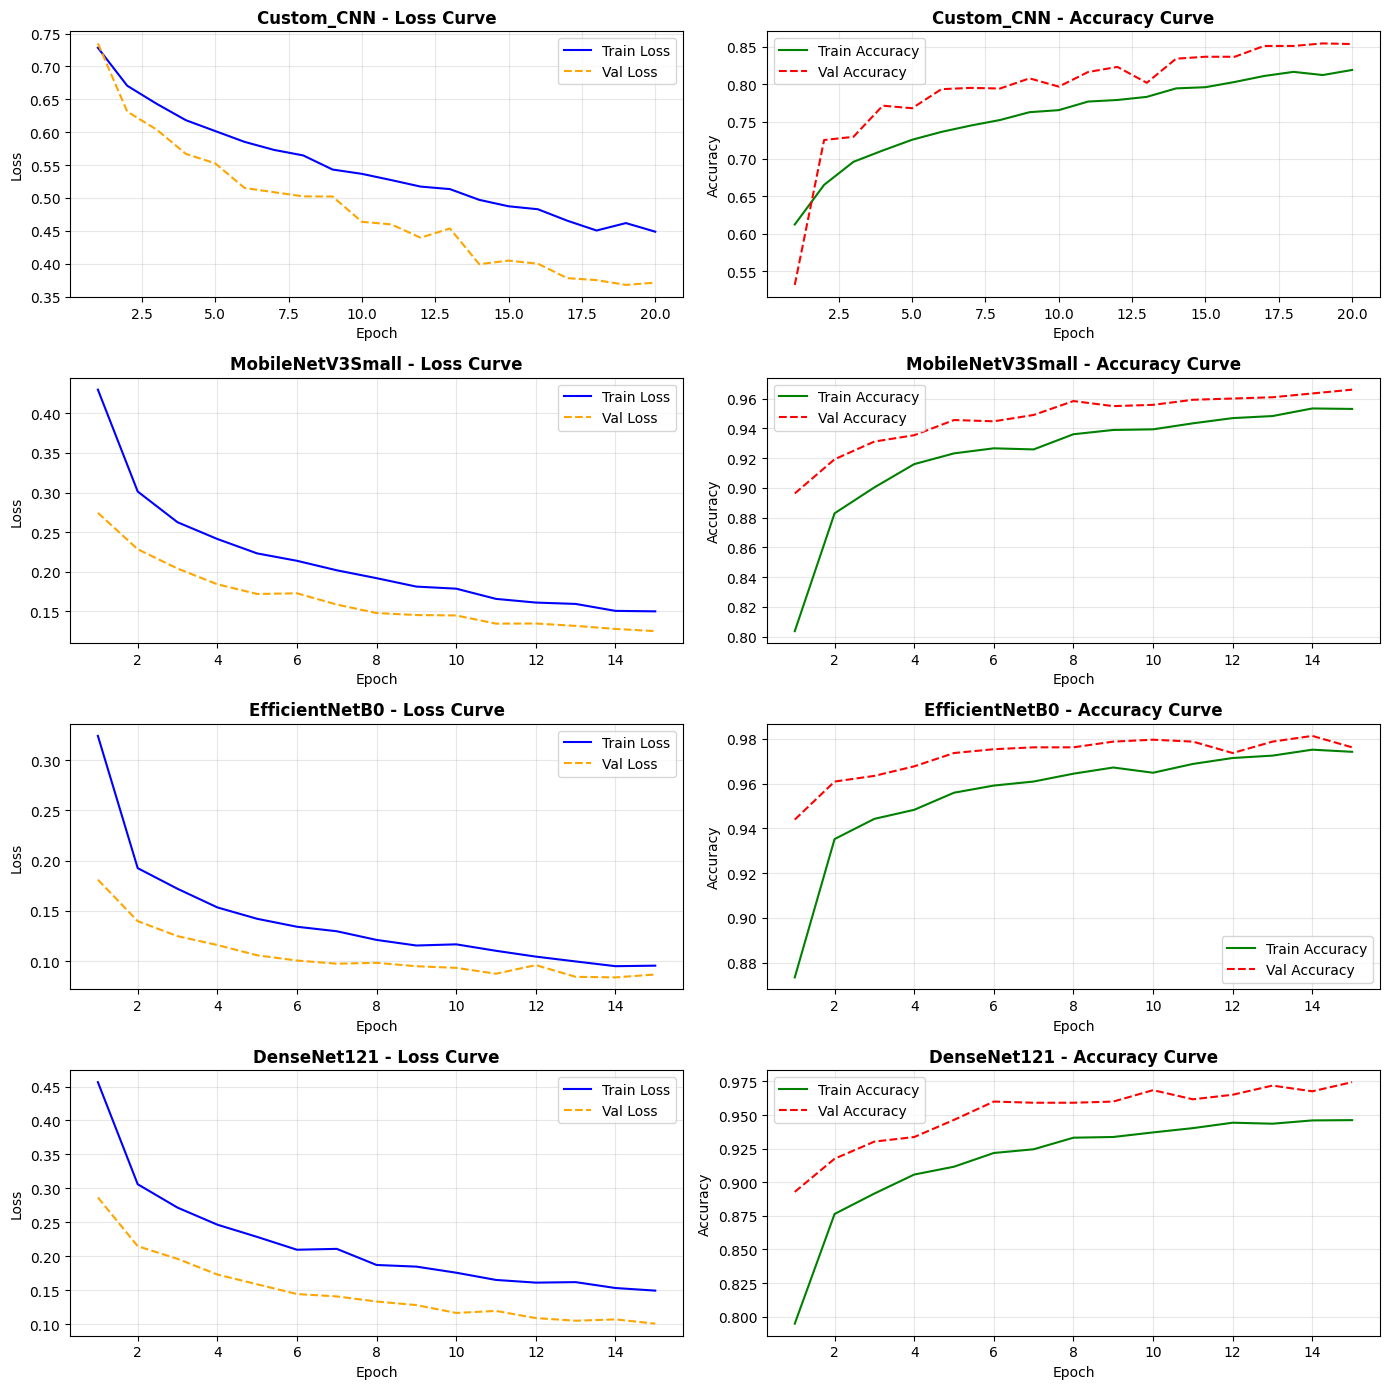

In [51]:
# Plot training and validation learning curves for all baseline models
if all_histories:
    fig, axes = plt.subplots(len(all_histories), 2, figsize=(14, 3.5 * len(all_histories)))
    for idx, (name, hist) in enumerate(all_histories.items()):
        # Loss plot
        axes[idx, 0].plot(hist['Epoch'], hist['loss'], label='Train Loss', color='blue')
        axes[idx, 0].plot(hist['Epoch'], hist['val_loss'], label='Val Loss', color='orange', linestyle='--')
        axes[idx, 0].set_title(f"{name} - Loss Curve", fontweight='bold')
        axes[idx, 0].set_xlabel("Epoch")
        axes[idx, 0].set_ylabel("Loss")
        axes[idx, 0].legend()
        axes[idx, 0].grid(alpha=0.3)

        # Accuracy plot
        axes[idx, 1].plot(hist['Epoch'], hist['accuracy'], label='Train Accuracy', color='green')
        axes[idx, 1].plot(hist['Epoch'], hist['val_accuracy'], label='Val Accuracy', color='red', linestyle='--')
        axes[idx, 1].set_title(f"{name} - Accuracy Curve", fontweight='bold')
        axes[idx, 1].set_xlabel("Epoch")
        axes[idx, 1].set_ylabel("Accuracy")
        axes[idx, 1].legend()
        axes[idx, 1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

## 6.7 Baseline Model Comparison

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


,Rank,Model,Parameters,Training Time (s),Training Loss,Training Accuracy,Validation Loss,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Validation ROC-AUC,Accuracy Gap
0,1,EfficientNetB0,4213668,1420.4,0.0956,0.9904,0.0869,0.9813,0.9876,0.9738,0.9813,0.9981,0.0091
1,2,DenseNet121,7168833,1839.8,0.1494,0.9793,0.1008,0.9745,0.9771,0.9703,0.9745,0.9968,0.0048
2,3,MobileNetV3Small,1013105,1168.2,0.1501,0.9765,0.1251,0.9660,0.9733,0.9563,0.9659,0.9943,0.0105
3,4,Custom_CNN,422881,2540.9,0.4487,0.8722,0.3713,0.8546,0.8878,0.8024,0.8538,0.9368,0.0176


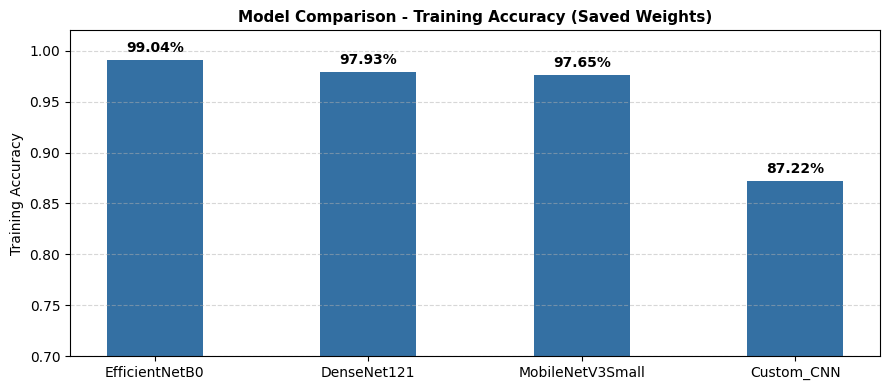

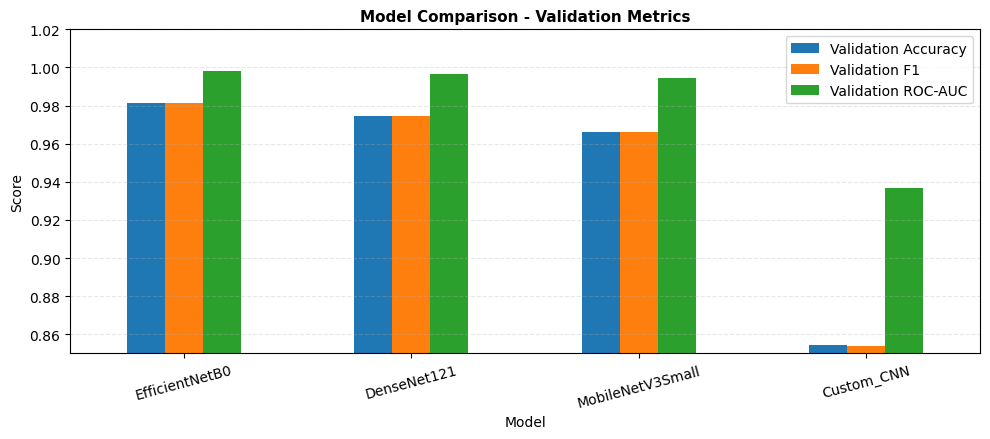

In [52]:
# Predict probabilities preserving exact DataFrame row order
def predict_ordered(model, loader, frame):
    probabilities = np.asarray(model.predict(loader, verbose=0)).reshape(-1)
    if len(probabilities) != len(frame) or not np.isfinite(probabilities).all():
        raise ValueError("Invalid predictions returned by model.")
    return probabilities


# Calculate full set of classification metrics at a given threshold
def calculate_metrics(targets, probabilities, threshold=DEFAULT_THRESHOLD):
    targets = np.asarray(targets, dtype=int)
    probabilities = np.asarray(probabilities, dtype=float)
    preds = (probabilities >= threshold).astype(int)
    cm = confusion_matrix(targets, preds, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    precisions, recalls, _ = precision_recall_curve(targets, probabilities)
    pr_auc = float(auc(recalls, precisions))

    return {
        'Threshold': float(threshold),
        'Accuracy': float(accuracy_score(targets, preds)),
        'Precision': float(precision_score(targets, preds, zero_division=0)),
        'Recall': float(recall_score(targets, preds, zero_division=0)),
        'Macro F1': float(f1_score(targets, preds, average='macro', zero_division=0)),
        'Rotten Recall': float(tp / (tp + fn)) if (tp + fn) > 0 else 0.0,
        'ROC-AUC': float(roc_auc_score(targets, probabilities)),
        'PR-AUC': pr_auc,
        'False Positives': int(fp),
        'False Negatives': int(fn),
        'Confusion Matrix': cm.tolist()
    }


# Evaluate saved model checkpoints on training and validation sets
comparison_rows = []
val_targets = val_data['target'].to_numpy()
train_targets = train_data['target'].to_numpy()

for name in MODELS_TO_TRAIN:
    model_path = MODELS_DIR / f"{name}.keras"
    model = keras.models.load_model(model_path, compile=False)

    train_probs = predict_ordered(model, train_eval_loader, train_data)
    val_probs = predict_ordered(model, val_loader, val_data)

    tm = calculate_metrics(train_targets, train_probs, DEFAULT_THRESHOLD)
    vm = calculate_metrics(val_targets, val_probs, DEFAULT_THRESHOLD)
    hist = all_histories.get(name, pd.DataFrame({'loss': [0.0], 'val_loss': [0.0]}))

    comparison_rows.append({
        'Model': name,
        'Parameters': int(model.count_params()),
        'Training Time (s)': round(training_times.get(name, 0.0), 1),
        'Training Loss': round(float(hist['loss'].iloc[-1]), 4),
        'Training Accuracy': round(tm['Accuracy'], 4),
        'Validation Loss': round(float(hist['val_loss'].iloc[-1]), 4),
        'Validation Accuracy': round(vm['Accuracy'], 4),
        'Validation Precision': round(vm['Precision'], 4),
        'Validation Recall': round(vm['Recall'], 4),
        'Validation F1': round(vm['Macro F1'], 4),
        'Validation ROC-AUC': round(vm['ROC-AUC'], 4),
        'Accuracy Gap': round(tm['Accuracy'] - vm['Accuracy'], 4),
    })

    del model
    gc.collect()
    keras.backend.clear_session()

comparison_df = pd.DataFrame(comparison_rows)
comparison_df = comparison_df.sort_values('Training Accuracy', ascending=False, kind='stable').reset_index(drop=True)
comparison_df.insert(0, 'Rank', np.arange(1, len(comparison_df) + 1))
display(comparison_df)

# Visual comparison: Training Accuracy of saved checkpoints
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(comparison_df['Model'], comparison_df['Training Accuracy'], color='#3470a3', width=0.45)
ax.set_title('Model Comparison - Training Accuracy (Saved Weights)', fontsize=11, fontweight='bold')
ax.set_ylabel('Training Accuracy')
ax.set_ylim(0.7, 1.02)
ax.grid(axis='y', linestyle='--', alpha=0.5)
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, yval + 0.005, f"{yval:.2%}", ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()

# Visual comparison: Validation Metrics
fig, ax = plt.subplots(figsize=(10, 4.5))
comparison_df.plot.bar(x='Model', y=['Validation Accuracy', 'Validation F1', 'Validation ROC-AUC'], ax=ax, rot=15)
ax.set_title('Model Comparison - Validation Metrics', fontsize=11, fontweight='bold')
ax.set_ylabel('Score')
ax.set_ylim(0.85, 1.02)
ax.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

## 6.8 Selection of the Winning Model


SELECTED BASELINE MODEL
Selected Model:       EfficientNetB0
Selection Criterion:  Highest Training Accuracy
Training Accuracy:    99.04%
Validation Accuracy:  98.13%
Validation F1-Score:  98.13%
Saved Checkpoint:     /content/drive/MyDrive/Food_Analysis_AI/models/EfficientNetB0.keras

--- Validation Analysis: EfficientNetB0 ---


,Setting,Threshold,Accuracy,Precision,Recall,Macro F1,Rotten Recall,ROC-AUC,PR-AUC,False Positives,False Negatives,Confusion Matrix
0,Default (0.50),0.50,0.981293,0.987589,0.973776,0.981271,0.973776,0.99809,0.998109,7,15,"[[597, 7], [15, 557]]"
1,Optimized Threshold,0.46,0.982143,0.984183,0.979021,0.982127,0.979021,0.99809,0.998109,9,12,"[[595, 9], [12, 560]]"


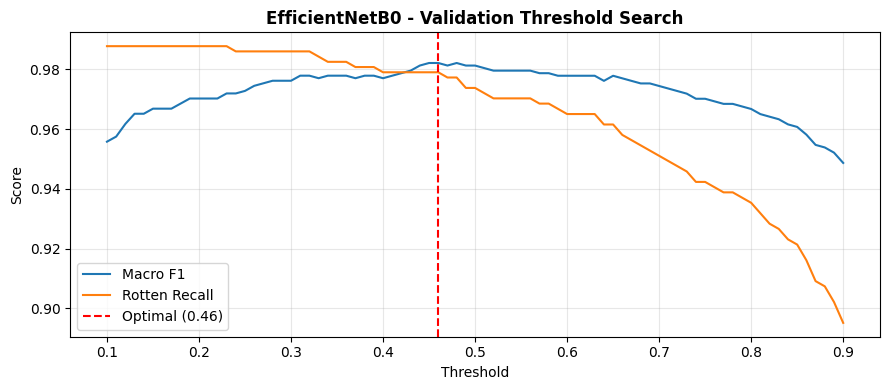

Total Validation Misclassifications: 21


,food_type,condition,predicted_condition,Errors
0,Apple,Rotten,Fresh,2
1,Bellpepper,Fresh,Rotten,1
2,Bellpepper,Rotten,Fresh,8
3,Carrot,Fresh,Rotten,1
4,Cucumber,Fresh,Rotten,2
5,Cucumber,Rotten,Fresh,1
6,Orange,Fresh,Rotten,1
7,Potato,Fresh,Rotten,2
8,Potato,Rotten,Fresh,1
9,Strawberry,Fresh,Rotten,1


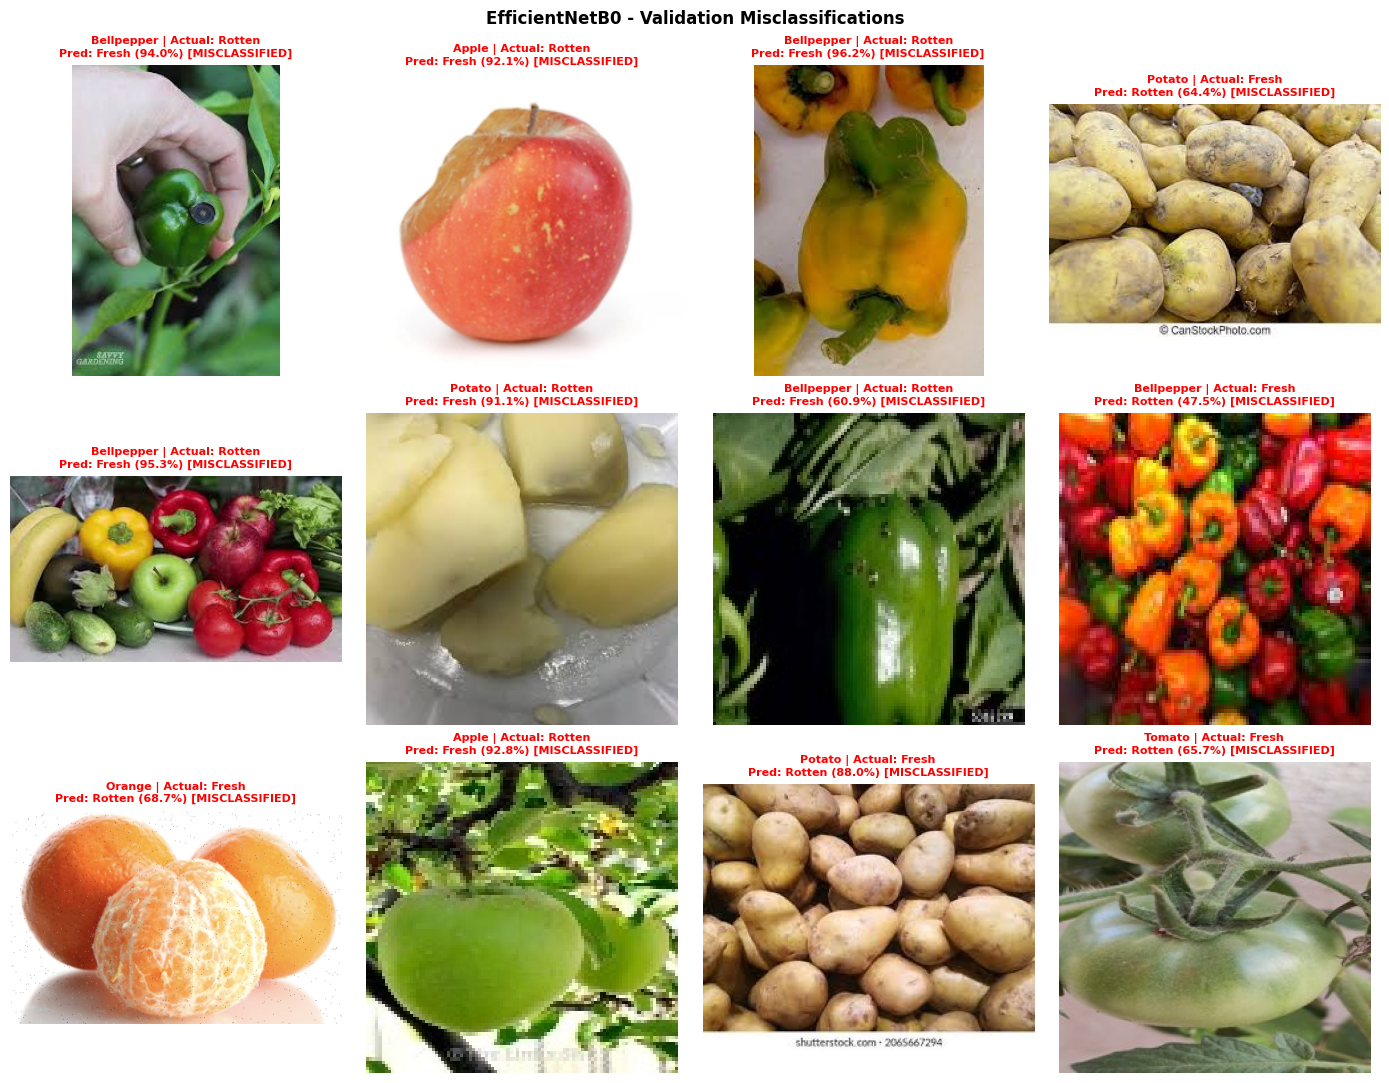

In [53]:
# Search for threshold that maximizes Macro F1 on validation predictions
def optimize_validation_threshold(targets, probabilities):
    rows = [calculate_metrics(targets, probabilities, float(t)) for t in THRESHOLDS]
    table = pd.DataFrame(rows)
    table['Distance to 0.50'] = (table['Threshold'] - DEFAULT_THRESHOLD).abs()
    ranked = table.sort_values(
        ['Macro F1', 'Rotten Recall', 'Distance to 0.50', 'Threshold'],
        ascending=[False, False, True, True],
        kind='stable'
    )
    return float(ranked.iloc[0]['Threshold']), table


# Build structured DataFrame for error analysis
def prediction_frame(frame, probabilities, threshold):
    result = frame[['path', 'food_type', 'condition', 'target']].reset_index(drop=True).copy()
    result['rotten_probability'] = probabilities
    result['predicted_target'] = (probabilities >= threshold).astype(int)
    result['predicted_condition'] = result['predicted_target'].map({0: 'Fresh', 1: 'Rotten'})
    result['is_correct'] = result['target'].eq(result['predicted_target'])
    return result


# Display sample grid of predictions or misclassifications
def show_prediction_samples(result, title, errors_only=False):
    sample = result.loc[~result['is_correct']] if errors_only else result
    if sample.empty:
        print(f"{title}: No samples found.")
        return
    sample = sample.sample(n=min(12, len(sample)), random_state=RANDOM_STATE)
    fig, axes = plt.subplots(3, 4, figsize=(14, 11))
    for ax in axes.flat:
        ax.axis('off')
    for ax, (_, row) in zip(axes.flat, sample.iterrows()):
        try:
            with Image.open(row['path']) as img:
                ax.imshow(img.convert('RGB'))
        except Exception:
            pass
        prob = row['rotten_probability'] if row['predicted_target'] == 1 else 1.0 - row['rotten_probability']
        color = 'green' if row['is_correct'] else 'red'
        status = 'Correct' if row['is_correct'] else 'MISCLASSIFIED'
        ax.set_title(f"{row['food_type']} | Actual: {row['condition']}\n"
                     f"Pred: {row['predicted_condition']} ({prob:.1%}) [{status}]",
                     fontsize=8, color=color, fontweight='bold')
    plt.suptitle(title, fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()


# Full validation analysis with threshold search and error breakdown
def validation_analysis(model_path, model_name):
    model = keras.models.load_model(model_path, compile=False)
    probabilities = predict_ordered(model, val_loader, val_data)
    del model
    gc.collect()
    keras.backend.clear_session()

    threshold, table = optimize_validation_threshold(val_data['target'], probabilities)
    fixed = calculate_metrics(val_data['target'], probabilities, DEFAULT_THRESHOLD)
    optimized = calculate_metrics(val_data['target'], probabilities, threshold)

    print(f"\n--- Validation Analysis: {model_name} ---")
    display(pd.DataFrame([
        {'Setting': 'Default (0.50)', **fixed},
        {'Setting': 'Optimized Threshold', **optimized}
    ]))

    # Threshold curve plot
    fig, ax = plt.subplots(figsize=(9, 4))
    table.plot(x='Threshold', y=['Macro F1', 'Rotten Recall'], ax=ax)
    ax.axvline(threshold, color='red', linestyle='--', label=f'Optimal ({threshold:.2f})')
    ax.set_title(f"{model_name} - Validation Threshold Search", fontweight='bold')
    ax.set_ylabel("Score")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Error analysis breakdown
    result = prediction_frame(val_data, probabilities, threshold)
    errors = result.loc[~result['is_correct']]
    if not errors.empty:
        print(f"Total Validation Misclassifications: {len(errors)}")
        display(errors.groupby(['food_type', 'condition', 'predicted_condition']).size().reset_index(name='Errors'))
        show_prediction_samples(result, f"{model_name} - Validation Misclassifications", errors_only=True)

    return {
        'model': model_name,
        'fixed': fixed,
        'optimized': optimized,
        'probabilities': probabilities
    }


# Select baseline winner by highest Training Accuracy
comparison_df = comparison_df.sort_values('Training Accuracy', ascending=False, kind='stable').reset_index(drop=True)
selected_row = comparison_df.iloc[0]
selected_model_name = str(selected_row['Model'])
selected_model_path = MODELS_DIR / f"{selected_model_name}.keras"

print("SELECTED BASELINE MODEL")
print(f"Selected Model:       {selected_model_name}")
print(f"Selection Criterion:  Highest Training Accuracy")
print(f"Training Accuracy:    {selected_row['Training Accuracy']:.2%}")
print(f"Validation Accuracy:  {selected_row['Validation Accuracy']:.2%}")
print(f"Validation F1-Score:  {selected_row['Validation F1']:.2%}")
print(f"Saved Checkpoint:     {selected_model_path}")

baseline_validation = validation_analysis(selected_model_path, selected_model_name)

## 6.9 EfficientNetB0 Fine-Tuning



### 6.9.1 Fine-Tuning Preparation, Training & Learning Curves


--- Fine-Tuning EfficientNetB0 ---
Prepared EfficientNetB0 fine-tuning: 15 backbone layers unfrozen (25 trainable weight tensors).
Epoch 1/10
146/295 ━━━━━━━━━━━━━━━━━━━━ 44s 296ms/step - accuracy: 0.9697 - loss: 0.1003 - precision: 0.9677 - recall: 0.9699 - roc_auc: 0.9966

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


295/295 ━━━━━━━━━━━━━━━━━━━━ 0s 280ms/step - accuracy: 0.9715 - loss: 0.0974 - precision: 0.9705 - recall: 0.9708 - roc_auc: 0.9969
Epoch 1: val_loss improved from None to 0.08430, saving model to /content/drive/MyDrive/Food_Analysis_AI/models/EfficientNetB0_finetuned.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Food_Analysis_AI/models/EfficientNetB0_finetuned.keras
295/295 ━━━━━━━━━━━━━━━━━━━━ 109s 330ms/step - accuracy: 0.9743 - loss: 0.0924 - precision: 0.9739 - recall: 0.9731 - roc_auc: 0.9974 - val_accuracy: 0.9813 - val_loss: 0.0843 - val_precision: 0.9928 - val_recall: 0.9685 - val_roc_auc: 0.9982 - learning_rate: 1.0000e-05
Epoch 2/10
295/295 ━━━━━━━━━━━━━━━━━━━━ 0s 280ms/step - accuracy: 0.9764 - loss: 0.0849 - precision: 0.9746 - recall: 0.9767 - roc_auc: 0.9979
Epoch 2: val_loss improved from 0.08430 to 0.07931, saving model to /content/drive/MyDrive/Food_Analysis_AI/models/EfficientNetB0_finetuned.keras

Epoch 2: finished saving model to /content/drive/My

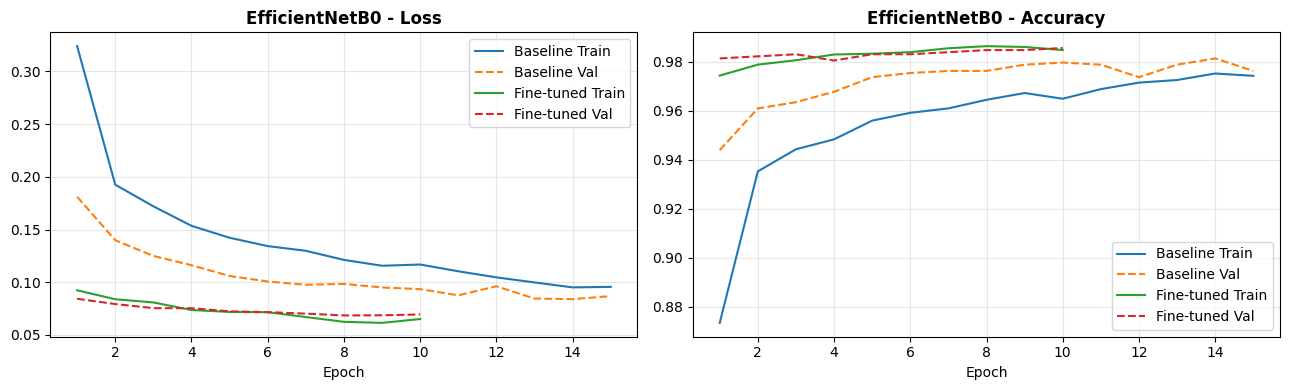

In [54]:
# Unfreeze top 15 weighted layers while keeping BatchNormalization frozen
def prepare_fine_tuning(model):
    backbones = [layer for layer in model.layers
                 if isinstance(layer, keras.Model) and 'efficientnet' in layer.name.lower()]
    if len(backbones) != 1:
        raise ValueError('Expected exactly one nested EfficientNetB0 backbone.')
    backbone = backbones[0]
    backbone.trainable = True
    for layer in backbone.layers:
        layer.trainable = False

    eligible = [layer for layer in backbone.layers
                if layer.weights and not isinstance(layer, (layers.BatchNormalization, layers.Normalization))]
    if len(eligible) < FINE_TUNE_LAYERS:
        raise ValueError('Not enough weighted backbone layers for fine-tuning.')

    chosen = eligible[-FINE_TUNE_LAYERS:]
    for layer in chosen:
        layer.trainable = True

    # Functional model reconstruction ensuring BatchNormalization operates in inference mode
    inputs = keras.Input(shape=(*IMAGE_SIZE, 3), name='normalized_rgb')
    x = inputs
    for layer in model.layers:
        if isinstance(layer, layers.InputLayer):
            continue
        x = layer(x, training=False) if layer is backbone else layer(x)

    tuned = keras.Model(inputs, x, name='EfficientNetB0_finetuned')
    compile_model(tuned, FINE_TUNE_LR)

    # Verify layer trainability and frozen BatchNormalization
    bn_trainable = [l.trainable for l in backbone.layers if isinstance(l, layers.BatchNormalization)]
    assert not any(bn_trainable), "BatchNormalization layers must remain frozen!"
    print(f"Prepared EfficientNetB0 fine-tuning: {len(chosen)} backbone layers unfrozen ({len(tuned.trainable_weights)} trainable weight tensors).")
    return tuned


print("\n--- Fine-Tuning EfficientNetB0 ---")
source_path = MODELS_DIR / 'EfficientNetB0.keras'
source = keras.models.load_model(source_path, compile=False)
tuned = prepare_fine_tuning(source)

fine_model_path = MODELS_DIR / 'EfficientNetB0_finetuned.keras'

fine_history = tuned.fit(
    train_loader,
    validation_data=val_loader,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=training_callbacks(fine_model_path),
    verbose=1
)

if not fine_model_path.is_file():
    tuned.save(fine_model_path)

fine_hist_df = pd.DataFrame(fine_history.history)
fine_hist_df.insert(0, 'Epoch', np.arange(1, len(fine_hist_df) + 1))
fine_hist_df.insert(1, 'Model', 'EfficientNetB0_finetuned')

del tuned, source
gc.collect()
keras.backend.clear_session()

# Compare Baseline vs Fine-tuned Learning Curves
if 'EfficientNetB0' in all_histories:
    base_hist = all_histories['EfficientNetB0']
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, metric in zip(axes, ['loss', 'accuracy']):
        ax.plot(base_hist['Epoch'], base_hist[metric], label='Baseline Train')
        ax.plot(base_hist['Epoch'], base_hist['val_' + metric], label='Baseline Val', linestyle='--')
        ax.plot(fine_hist_df['Epoch'], fine_hist_df[metric], label='Fine-tuned Train')
        ax.plot(fine_hist_df['Epoch'], fine_hist_df['val_' + metric], label='Fine-tuned Val', linestyle='--')
        ax.set_title(f"EfficientNetB0 - {metric.capitalize()}", fontweight='bold')
        ax.set_xlabel("Epoch")
        ax.legend()
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

### 6.9.2 Fine-Tuned Validation Evaluation & Final Model Selection


--- Validation Analysis: EfficientNetB0_finetuned ---


,Setting,Threshold,Accuracy,Precision,Recall,Macro F1,Rotten Recall,ROC-AUC,PR-AUC,False Positives,False Negatives,Confusion Matrix
0,Default (0.50),0.5,0.984694,0.992883,0.975524,0.984674,0.975524,0.998932,0.998932,4,14,"[[600, 4], [14, 558]]"
1,Optimized Threshold,0.3,0.985544,0.982609,0.987762,0.985535,0.987762,0.998932,0.998932,10,7,"[[594, 10], [7, 565]]"


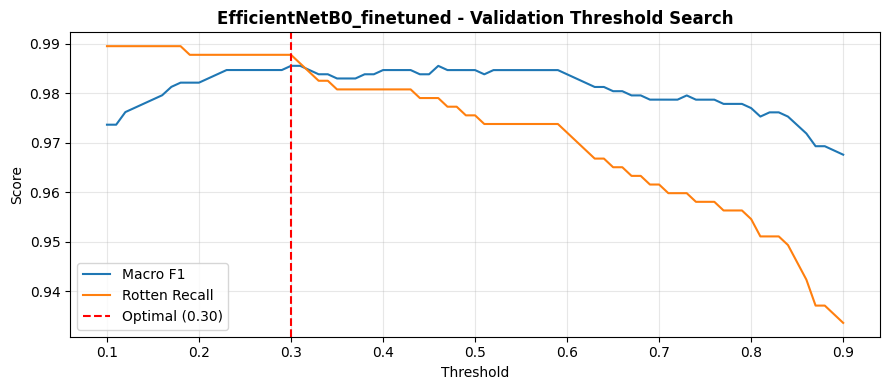


Total Correct Validation Predictions: 1,159 / 1,176 (98.55%)


,food_type,condition,predicted_condition,Correct Count
0,Apple,Fresh,Fresh,60
1,Apple,Rotten,Rotten,56
2,Banana,Fresh,Fresh,62
3,Banana,Rotten,Rotten,58
4,Bellpepper,Fresh,Fresh,59
5,Bellpepper,Rotten,Rotten,51
6,Carrot,Fresh,Fresh,59
7,Carrot,Rotten,Rotten,51
8,Cucumber,Fresh,Fresh,57
9,Cucumber,Rotten,Rotten,58


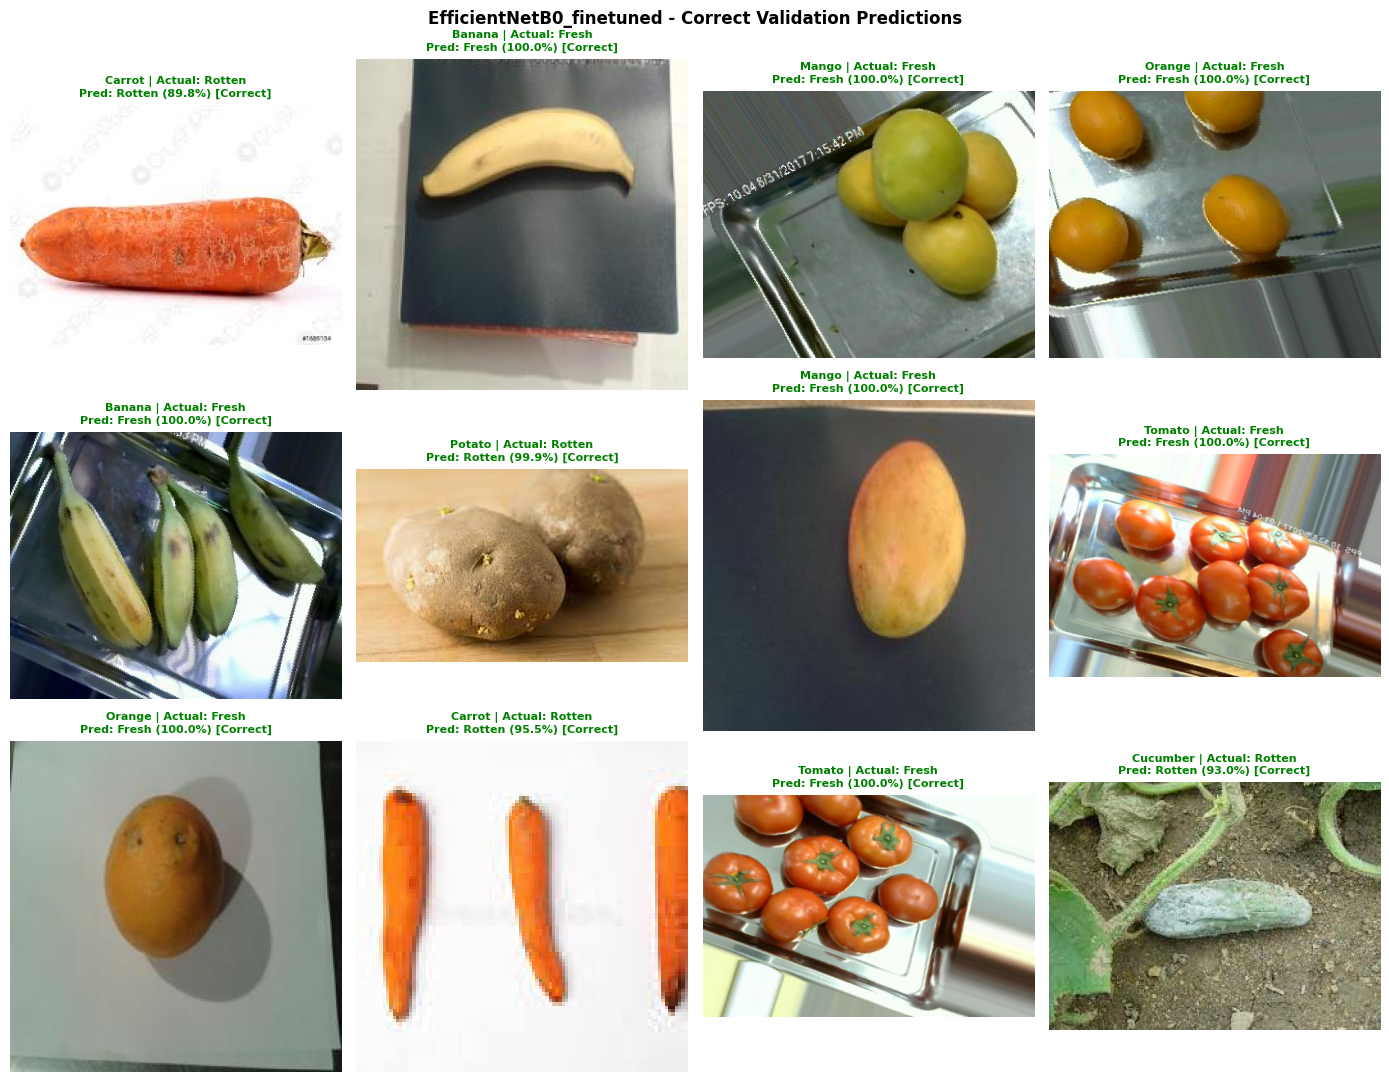

,Model,Setting,Threshold,Accuracy,Macro F1,Rotten Recall,False Negatives,False Positives
0,Baseline (EfficientNetB0),fixed,0.50,0.981293,0.981271,0.973776,15,7
1,Baseline (EfficientNetB0),optimized,0.46,0.982143,0.982127,0.979021,12,9
2,Fine-Tuned (EfficientNetB0),fixed,0.50,0.984694,0.984674,0.975524,14,4
3,Fine-Tuned (EfficientNetB0),optimized,0.30,0.985544,0.985535,0.987762,7,10



FINAL DEPLOYMENT MODEL SELECTED (VALIDATION LOCKED)
Winning Model:         EfficientNetB0_finetuned
Optimal Threshold:     0.30
Validation Macro F1:   98.55%
Validation Recall:     98.78%
Saved Checkpoint:      /content/drive/MyDrive/Food_Analysis_AI/models/EfficientNetB0_finetuned.keras


In [67]:
# Evaluate fine-tuned model on validation set
model = keras.models.load_model(fine_model_path, compile=False)
fine_val_probs = predict_ordered(model, val_loader, val_data)
del model
gc.collect()
keras.backend.clear_session()

fine_threshold, fine_table = optimize_validation_threshold(val_data['target'], fine_val_probs)
fine_fixed = calculate_metrics(val_data['target'], fine_val_probs, DEFAULT_THRESHOLD)
fine_optimized = calculate_metrics(val_data['target'], fine_val_probs, fine_threshold)

print("\n--- Validation Analysis: EfficientNetB0_finetuned ---")
display(pd.DataFrame([
    {'Setting': 'Default (0.50)', **fine_fixed},
    {'Setting': 'Optimized Threshold', **fine_optimized}
]))

# Validation threshold search curve
fig, ax = plt.subplots(figsize=(9, 4))
fine_table.plot(x='Threshold', y=['Macro F1', 'Rotten Recall'], ax=ax)
ax.axvline(fine_threshold, color='red', linestyle='--', label=f'Optimal ({fine_threshold:.2f})')
ax.set_title("EfficientNetB0_finetuned - Validation Threshold Search", fontweight='bold')
ax.set_ylabel("Score")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Display correctly predicted validation samples visually
fine_val_df = prediction_frame(val_data, fine_val_probs, fine_threshold)
correct_samples = fine_val_df.loc[fine_val_df['is_correct']]

print(f"\nTotal Correct Validation Predictions: {len(correct_samples):,} / {len(fine_val_df):,} ({len(correct_samples)/len(fine_val_df):.2%})")
display(correct_samples.groupby(['food_type', 'condition', 'predicted_condition']).size().reset_index(name='Correct Count'))
show_prediction_samples(correct_samples, "EfficientNetB0_finetuned - Correct Validation Predictions", errors_only=False)

fine_validation = {
    'model': 'EfficientNetB0_finetuned',
    'fixed': fine_fixed,
    'optimized': fine_optimized,
    'probabilities': fine_val_probs
}

# Compare Baseline vs Fine-Tuned performance on validation data
val_comp_rows = []
for name, result in [('Baseline (' + selected_model_name + ')', baseline_validation),
                     ('Fine-Tuned (EfficientNetB0)', fine_validation)]:
    for setting in ['fixed', 'optimized']:
        val_comp_rows.append({'Model': name, 'Setting': setting, **result[setting]})

val_comp_df = pd.DataFrame(val_comp_rows)
display(val_comp_df[['Model', 'Setting', 'Threshold', 'Accuracy', 'Macro F1',
                     'Rotten Recall', 'False Negatives', 'False Positives']])

# Select final winning model based on Validation Macro F1, then Rotten Recall
candidates = [(selected_model_path, baseline_validation), (fine_model_path, fine_validation)]
final_model_path, final_val = max(candidates, key=lambda p: (
    p[1]['optimized']['Macro F1'], p[1]['optimized']['Rotten Recall']
))

final_model_name = final_val['model']
final_threshold = float(final_val['optimized']['Threshold'])

print("\nFINAL DEPLOYMENT MODEL SELECTED (VALIDATION LOCKED)")
print(f"Winning Model:         {final_model_name}")
print(f"Optimal Threshold:     {final_threshold:.2f}")
print(f"Validation Macro F1:   {final_val['optimized']['Macro F1']:.2%}")
print(f"Validation Recall:     {final_val['optimized']['Rotten Recall']:.2%}")
print(f"Saved Checkpoint:      {final_model_path}")

## 6.10 Model Testing & Evaluation (Selected Model Only)



### 6.10.1 Final Test Evaluation & Classification Report

In [56]:
# Load final winning model for isolated test evaluation
final_eval_model = keras.models.load_model(final_model_path, compile=False)
test_probs = predict_ordered(final_eval_model, test_loader, test_data)
test_targets = test_data['target'].to_numpy(dtype=int)
test_preds = (test_probs >= final_threshold).astype(int)

test_metrics = calculate_metrics(test_targets, test_probs, final_threshold)

print("FINAL TEST EVALUATION (ISOLATED TEST SET)")
print(f"Model:                {final_model_name}")
print(f"Applied Threshold:    {final_threshold:.2f}")
print(f"Test Accuracy:        {test_metrics['Accuracy']:.2%}")
print(f"Test Macro F1:        {test_metrics['Macro F1']:.2%}")
print(f"Test Rotten Recall:   {test_metrics['Rotten Recall']:.2%}")
print(f"Test ROC-AUC:         {test_metrics['ROC-AUC']:.2%}")
print(f"Test PR-AUC:          {test_metrics['PR-AUC']:.2%}")
print(f"False Negatives:      {test_metrics['False Negatives']}")
print(f"False Positives:      {test_metrics['False Positives']}")

print("\nClassification Report (Test):")
print(classification_report(test_targets, test_preds, target_names=['Fresh (0)', 'Rotten (1)'], digits=4))

FINAL TEST EVALUATION (ISOLATED TEST SET)
Model:                EfficientNetB0_finetuned
Applied Threshold:    0.30
Test Accuracy:        98.22%
Test Macro F1:        98.21%
Test Rotten Recall:   97.89%
Test ROC-AUC:         99.80%
Test PR-AUC:          99.81%
False Negatives:      12
False Positives:      9

Classification Report (Test):
              precision    recall  f1-score   support

   Fresh (0)     0.9804    0.9852    0.9828       608
  Rotten (1)     0.9841    0.9789    0.9815       569

    accuracy                         0.9822      1177
   macro avg     0.9822    0.9821    0.9821      1177
weighted avg     0.9822    0.9822    0.9822      1177



### 6.10.2 Confusion Matrix, ROC & Precision-Recall Curves

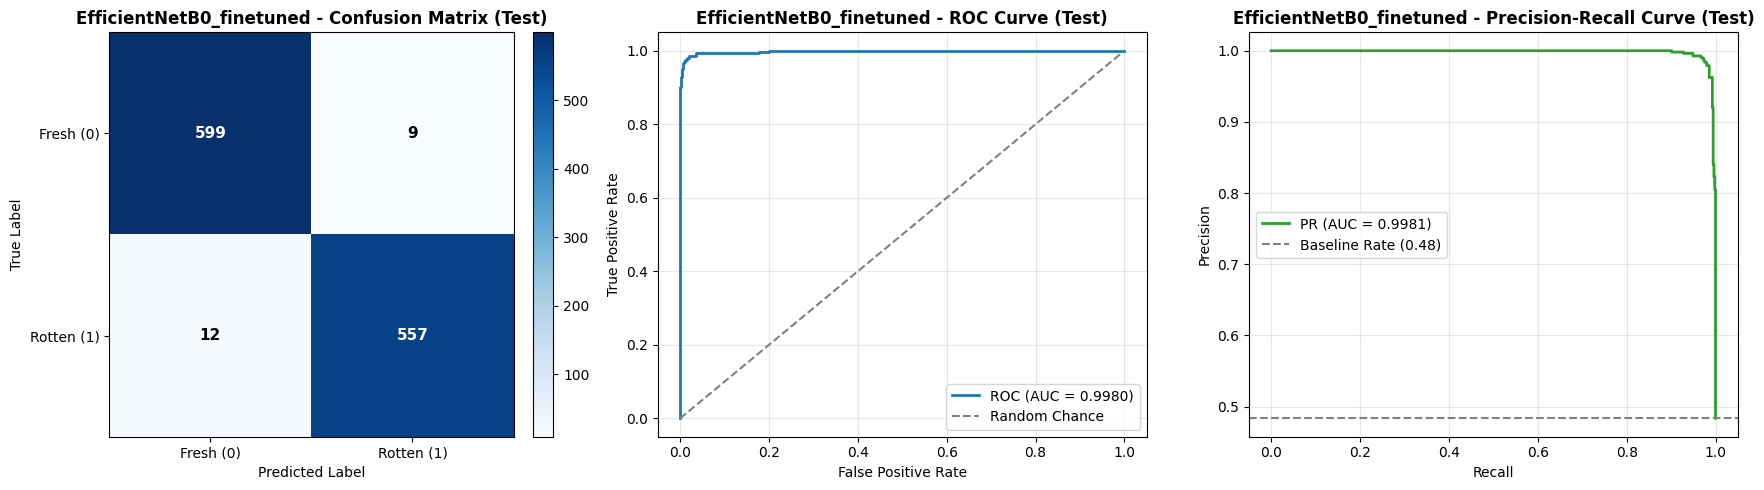

In [57]:
# Plot Confusion Matrix, ROC Curve, and Precision-Recall Curve
cm = confusion_matrix(test_targets, test_preds, labels=[0, 1])
fpr, tpr, _ = roc_curve(test_targets, test_probs)
precisions, recalls, _ = precision_recall_curve(test_targets, test_probs)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Confusion Matrix
im = axes[0].imshow(cm, cmap='Blues')
axes[0].set_title(f"{final_model_name} - Confusion Matrix (Test)", fontweight='bold')
axes[0].set_xticks([0, 1])
axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(['Fresh (0)', 'Rotten (1)'])
axes[0].set_yticklabels(['Fresh (0)', 'Rotten (1)'])
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, f"{cm[i, j]:,}", ha='center', va='center',
                     color='white' if cm[i, j] > cm.max() / 2 else 'black', fontweight='bold', fontsize=11)
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

# 2. ROC Curve
axes[1].plot(fpr, tpr, color='#1f77b4', lw=2, label=f"ROC (AUC = {test_metrics['ROC-AUC']:.4f})")
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1.5, label='Random Chance')
axes[1].set_title(f"{final_model_name} - ROC Curve (Test)", fontweight='bold')
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend()
axes[1].grid(alpha=0.3)

# 3. Precision-Recall Curve
axes[2].plot(recalls, precisions, color='#2ca02c', lw=2, label=f"PR (AUC = {test_metrics['PR-AUC']:.4f})")
base_rate = test_targets.mean()
axes[2].axhline(base_rate, color='gray', linestyle='--', lw=1.5, label=f'Baseline Rate ({base_rate:.2f})')
axes[2].set_title(f"{final_model_name} - Precision-Recall Curve (Test)", fontweight='bold')
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 6.11 Baseline / Fine-Tuned Test Comparison





,Configuration,Threshold,Accuracy,Macro F1,Precision,Recall,Rotten Recall,ROC-AUC,PR-AUC,False Negatives,False Positives
0,Baseline (EfficientNetB0) @ 0.50,0.50,0.976211,0.976179,0.978761,0.971880,0.971880,0.997199,0.997339,16,12
1,Baseline (EfficientNetB0) @ Optimal (0.46),0.46,0.976211,0.976182,0.977072,0.973638,0.973638,0.997199,0.997339,15,13
2,Fine-Tuned (EfficientNetB0) @ Optimal (0.30),0.30,0.982158,0.982135,0.984099,0.978910,0.978910,0.998040,0.998111,12,9
3,Final Selected Deployment Model (EfficientNetB...,0.30,0.982158,0.982135,0.984099,0.978910,0.978910,0.998040,0.998111,12,9


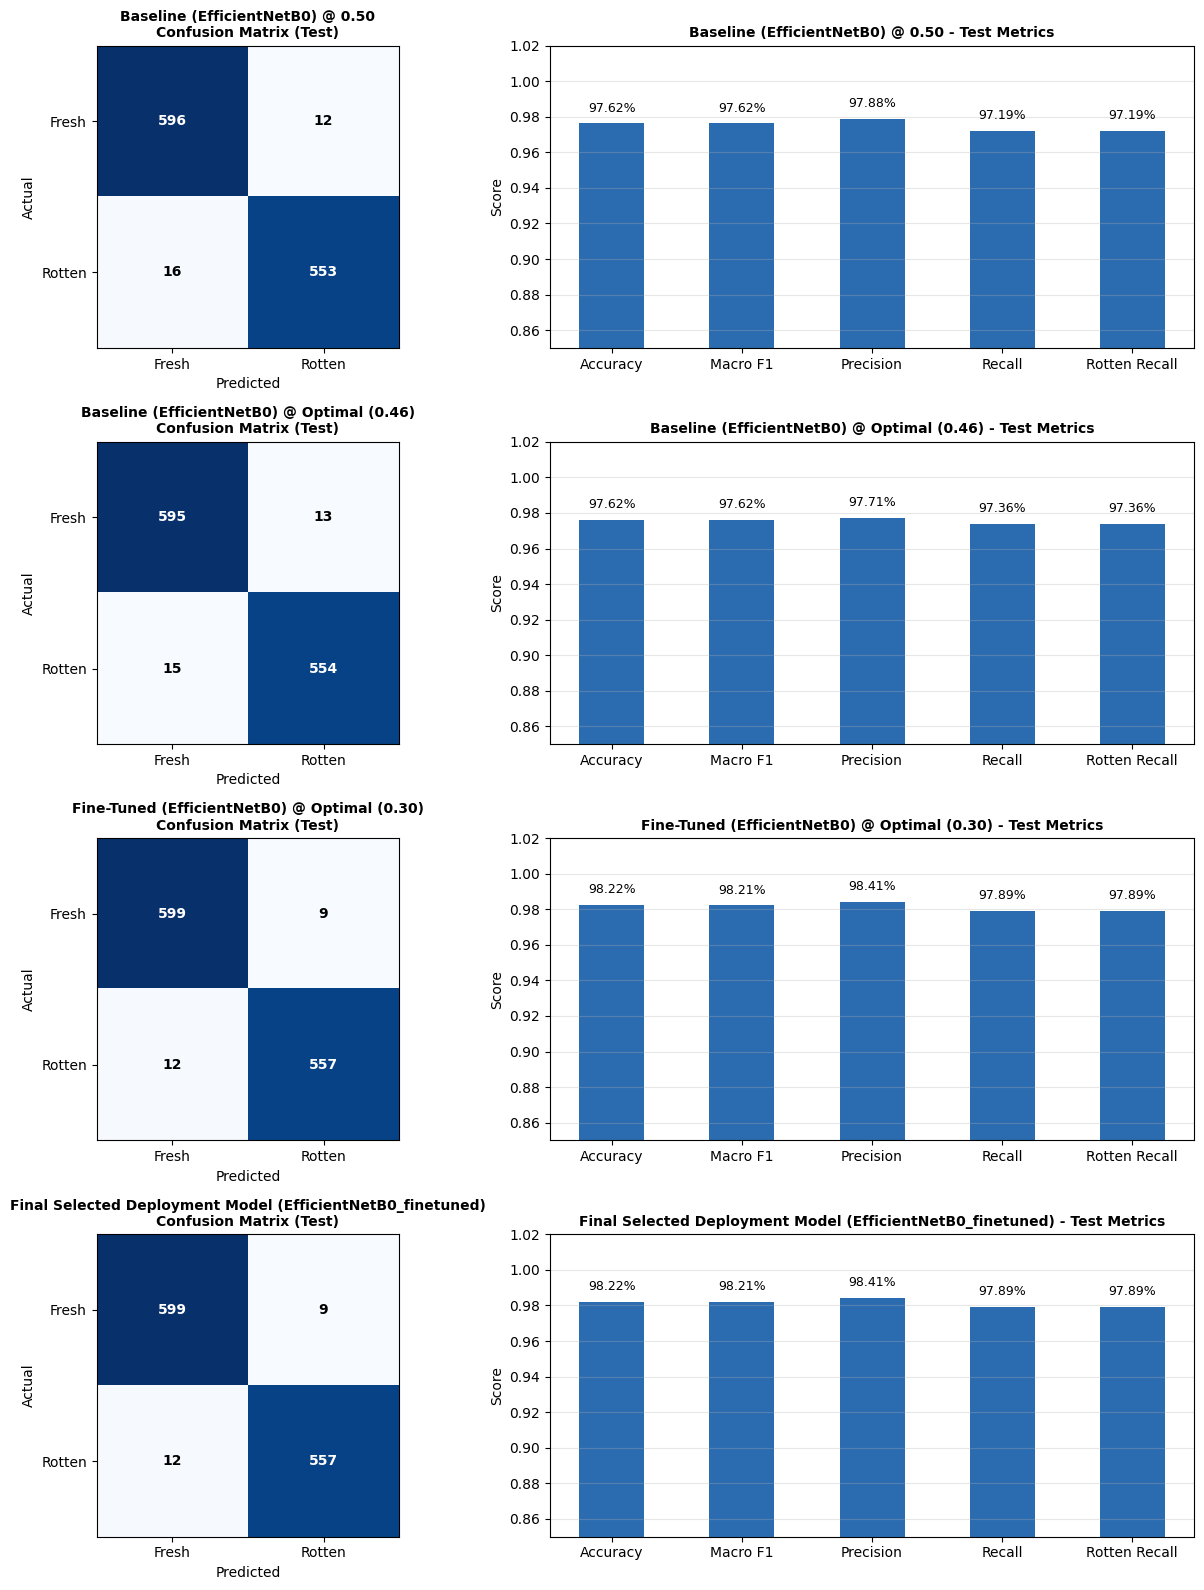

In [59]:
# Compare Baseline vs Fine-Tuned models on the isolated test set
test_comparison_specs = [
    (f"Baseline ({selected_model_name}) @ 0.50", selected_model_path, DEFAULT_THRESHOLD),
    (f"Baseline ({selected_model_name}) @ Optimal ({baseline_validation['optimized']['Threshold']:.2f})",
     selected_model_path, baseline_validation['optimized']['Threshold']),
    (f"Fine-Tuned (EfficientNetB0) @ Optimal ({fine_validation['optimized']['Threshold']:.2f})",
     fine_model_path, fine_validation['optimized']['Threshold']),
    (f"Final Selected Deployment Model ({final_model_name})",
     final_model_path, final_threshold),
]

prob_cache = {}
test_evaluations = {}

for label, path, thresh in test_comparison_specs:
    k = str(path)
    if k not in prob_cache:
        m = keras.models.load_model(path, compile=False)
        prob_cache[k] = predict_ordered(m, test_loader, test_data)
        del m
        gc.collect()
        keras.backend.clear_session()
    probs = prob_cache[k]
    test_evaluations[label] = calculate_metrics(test_targets, probs, thresh)

test_comp_df = pd.DataFrame([
    {'Configuration': lbl, **m} for lbl, m in test_evaluations.items()
])
display(test_comp_df[['Configuration', 'Threshold', 'Accuracy', 'Macro F1', 'Precision',
                      'Recall', 'Rotten Recall', 'ROC-AUC', 'PR-AUC', 'False Negatives', 'False Positives']])

# Side-by-side test confusion matrices and metrics comparison
fig, axes = plt.subplots(len(test_evaluations), 2, figsize=(13, 4 * len(test_evaluations)), squeeze=False)
for idx, (label, entry) in enumerate(test_evaluations.items()):
    matrix = np.asarray(entry['Confusion Matrix'])
    # Confusion matrix
    axes[idx, 0].imshow(matrix, cmap='Blues')
    axes[idx, 0].set_title(f"{label}\nConfusion Matrix (Test)", fontsize=10, fontweight='bold')
    axes[idx, 0].set_xticks([0, 1])
    axes[idx, 0].set_yticks([0, 1])
    axes[idx, 0].set_xticklabels(['Fresh', 'Rotten'])
    axes[idx, 0].set_yticklabels(['Fresh', 'Rotten'])
    axes[idx, 0].set_xlabel('Predicted')
    axes[idx, 0].set_ylabel('Actual')
    for r in range(2):
        for c in range(2):
            axes[idx, 0].text(c, r, f"{matrix[r, c]:,}", ha='center', va='center',
                              color='white' if matrix[r, c] > matrix.max() / 2 else 'black', fontweight='bold')

    # Metrics bar chart
    metric_keys = ['Accuracy', 'Macro F1', 'Precision', 'Recall', 'Rotten Recall']
    metric_vals = [entry[k] for k in metric_keys]
    bars = axes[idx, 1].bar(metric_keys, metric_vals, color='#2b6cb0', width=0.5)
    axes[idx, 1].set_title(f"{label} - Test Metrics", fontsize=10, fontweight='bold')
    axes[idx, 1].set_ylim(0.85, 1.02)
    axes[idx, 1].set_ylabel('Score')
    axes[idx, 1].grid(axis='y', alpha=0.3)
    for b in bars:
        h = b.get_height()
        axes[idx, 1].text(b.get_x() + b.get_width() / 2, h + 0.005, f"{h:.2%}", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

## 6.12 Model Saving & Deployment Configuration

In [60]:
# Save complete deployment configuration for production inference
final_config = {
    'model_file': final_model_path.name,
    'model_name': final_model_name,
    'threshold': float(final_threshold),
    'image_size': list(IMAGE_SIZE),
    'label_map': LABEL_MAP,
    'class_names': ['Fresh', 'Rotten'],
    'preprocessing': {
        'color_mode': 'RGB',
        'rescale': '1/255.0',
        'interpolation': 'bilinear'
    },
    'selection_metric': 'Validation Macro F1, then Rotten Recall',
    'baseline_model': selected_model_name,
    'baseline_threshold': float(baseline_validation['optimized']['Threshold']),
    'fine_threshold': float(fine_validation['optimized']['Threshold']),
    'test_accuracy': float(test_metrics['Accuracy']),
    'test_macro_f1': float(test_metrics['Macro F1']),
    'test_rotten_recall': float(test_metrics['Rotten Recall']),
    'test_roc_auc': float(test_metrics['ROC-AUC']),
    'test_pr_auc': float(test_metrics['PR-AUC'])
}

with open(FINAL_CONFIG_PATH, 'w', encoding='utf-8') as f:
    json.dump(final_config, f, indent=2)

print("DEPLOYMENT CONFIGURATION SAVED")
print(f"Destination:          {FINAL_CONFIG_PATH}")
print(f"Selected Model File:  {final_config['model_file']}")
print(f"Decision Threshold:   {final_config['threshold']:.2f}")

# Verify all saved models in Google Drive directory
expected_files = [
    MODELS_DIR / f"{name}.keras" for name in MODELS_TO_TRAIN
] + [MODELS_DIR / 'EfficientNetB0_finetuned.keras', FINAL_CONFIG_PATH]

print("\n--- Saved Artifacts Verification ---")
for p in expected_files:
    status = "EXISTS" if p.is_file() else "MISSING"
    size_str = f"({p.stat().st_size / (1024*1024):.1f} MB)" if p.is_file() else ""
    print(f"[{status:7s}] {p.name} {size_str}")

DEPLOYMENT CONFIGURATION SAVED
Destination:          /content/drive/MyDrive/Food_Analysis_AI/models/final_config.json
Selected Model File:  EfficientNetB0_finetuned.keras
Decision Threshold:   0.30

--- Saved Artifacts Verification ---
[EXISTS ] Custom_CNN.keras (4.9 MB)
[EXISTS ] MobileNetV3Small.keras (5.0 MB)
[EXISTS ] EfficientNetB0.keras (18.2 MB)
[EXISTS ] DenseNet121.keras (29.8 MB)
[EXISTS ] EfficientNetB0_finetuned.keras (33.9 MB)
[EXISTS ] final_config.json (0.0 MB)


## 6.13 Load Saved Model



In [61]:
import json
from pathlib import Path
import tensorflow as tf
from tensorflow import keras

# Load a trained model checkpoint and its deployment configuration
def load_saved_model(model_dir=None):
    if model_dir is None:
        model_dir = Path('/content/drive/MyDrive/Food_Analysis_AI/models')
    else:
        model_dir = Path(model_dir)

    # Mount Google Drive if in Google Colab and directory is not yet mounted
    if not model_dir.exists() and str(model_dir).startswith('/content/drive'):
        try:
            from google.colab import drive
            drive.mount('/content/drive')
        except ImportError:
            pass

    config_path = model_dir / 'final_config.json'
    if not config_path.is_file():
        raise FileNotFoundError(f"Configuration file not found: {config_path}")

    with open(config_path, 'r', encoding='utf-8') as f:
        config = json.load(f)

    model_file = config.get('model_file', 'EfficientNetB0_finetuned.keras')
    model_path = model_dir / model_file
    if not model_path.is_file():
        raise FileNotFoundError(f"Model checkpoint not found: {model_path}")

    model = keras.models.load_model(model_path, compile=False)

    print(f"Loaded {config.get('model_name', model_file)} from {model_path.name}")
    print(f"Optimal decision threshold: {config['threshold']:.2f}")
    print(f"Input image dimensions:     {config['image_size']}")
    print(f"Class mapping:              {config['label_map']}")
    print("Model is ready for inference.")

    return model, config


model, config = load_saved_model()

Loaded EfficientNetB0_finetuned from EfficientNetB0_finetuned.keras
Optimal decision threshold: 0.30
Input image dimensions:     [224, 224]
Class mapping:              {'Fresh': 0, 'Rotten': 1}
Model is ready for inference.


## 6.14 External Image Prediction


Upload one or more food images to classify:


Saving dgomoa1g-720.jpg to dgomoa1g-720.jpg

Result for: dgomoa1g-720.jpg


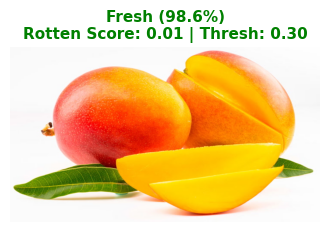

{'predicted_class': 'Fresh', 'rotten_probability': 0.0136, 'confidence': 0.9864, 'threshold': 0.3, 'is_rotten': False}


[{'predicted_class': 'Fresh',
  'rotten_probability': 0.0136,
  'confidence': 0.9864,
  'threshold': 0.3,
  'is_rotten': False}]

In [65]:
import io
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

SUPPORTED_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.webp'}

# Preprocess an external image for model prediction
def preprocess_external_image(image_input, target_size=(224, 224)):
    if isinstance(image_input, (str, Path)):
        p = Path(image_input)
        if not p.is_file():
            raise FileNotFoundError(f"Image file not found: {p}")
        if p.suffix.lower() not in SUPPORTED_EXTENSIONS:
            raise ValueError(f"Unsupported format '{p.suffix}'. Supported: {sorted(SUPPORTED_EXTENSIONS)}")

    try:
        if isinstance(image_input, Image.Image):
            img = image_input.convert('RGB')
        else:
            img = Image.open(image_input).convert('RGB')
    except Exception as err:
        raise ValueError(f"Cannot decode image: {err}") from err

    img = img.resize(target_size, Image.Resampling.BILINEAR)
    arr = np.asarray(img, dtype=np.float32) / 255.0
    return np.expand_dims(arr, axis=0)


# Predict classification for an external food image
def predict_image(image_input, model, config):
    target_size = tuple(config.get('image_size', (224, 224)))
    threshold = float(config.get('threshold', 0.50))

    batch = preprocess_external_image(image_input, target_size=target_size)
    raw_output = model.predict(batch, verbose=0)
    rotten_prob = float(raw_output[0, 0])

    is_rotten = rotten_prob >= threshold
    predicted_class = 'Rotten' if is_rotten else 'Fresh'
    confidence = rotten_prob if is_rotten else (1.0 - rotten_prob)

    return {
        'predicted_class': predicted_class,
        'rotten_probability': round(rotten_prob, 4),
        'confidence': round(confidence, 4),
        'threshold': round(threshold, 4),
        'is_rotten': is_rotten
    }


# Predict and visualize image with prediction badge
def predict_and_display(image_input, model, config):
    result = predict_image(image_input, model, config)

    if isinstance(image_input, (str, Path)):
        img = Image.open(image_input).convert('RGB')
    elif isinstance(image_input, Image.Image):
        img = image_input.convert('RGB')
    else:
        image_input.seek(0)
        img = Image.open(image_input).convert('RGB')

    plt.figure(figsize=(4, 4))
    plt.imshow(img)
    plt.axis('off')
    color = 'red' if result['is_rotten'] else 'green'
    plt.title(f"{result['predicted_class']} ({result['confidence']:.1%})\nRotten Score: {result['rotten_probability']:.2f} | Thresh: {result['threshold']:.2f}",
              color=color, fontsize=11, fontweight='bold')
    plt.show()
    return result


# Interactive prediction runner (path or Colab upload)
def run_prediction(image_path=None):
    if 'model' not in globals() or 'config' not in globals():
        loaded_model, loaded_config = load_saved_model()
    else:
        loaded_model, loaded_config = model, config

    if image_path and Path(image_path).is_file():
        return predict_and_display(image_path, loaded_model, loaded_config)

    try:
        from google.colab import files
        print("Upload one or more food images to classify:")
        uploaded = files.upload()
        results = []
        for name, data in uploaded.items():
            print(f"\nResult for: {name}")
            res = predict_and_display(io.BytesIO(data), loaded_model, loaded_config)
            print(res)
            results.append(res)
        return results
    except ImportError:
        print("Specify image_path when running outside Google Colab.")
        return None


run_prediction()